In [1]:
%pip install numpy pandas matplotlib nibabel nilearn scipy statsmodels fsspec requests

Note: you may need to restart the kernel to use updated packages.


In [2]:

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
import nilearn
import scipy
import statsmodels
import fsspec

print("All libraries imported successfully!")
print("NiBabel version:", nib.__version__)
print("Nilearn version:", nilearn.__version__)


All libraries imported successfully!
NiBabel version: 5.4.2
Nilearn version: 0.14.1


In [3]:

from pathlib import Path

PROJECT_DIR = Path.home() / "Documents" / "NSCI270_Hippocampus"

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = PROJECT_DIR / "figures"

for folder in [DATA_DIR, OUTPUT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Folders created successfully!")


Project directory: C:\Users\risha\Documents\NSCI270_Hippocampus
Folders created successfully!


In [4]:

import fsspec

DATASET = "ds004302"
VERSION = "1.0.1"

fs = fsspec.filesystem("s3", anon=True)

bucket_path = f"openneuro.org/{DATASET}"

try:
    files = fs.find(bucket_path)
    print("Connection successful!")
    print("Total objects found:", len(files))
except Exception as e:
    print("Connection error:", repr(e))


Connection successful!
Total objects found: 152


In [5]:

t1_files = sorted([
    f for f in files
    if f.endswith("_T1w.nii.gz")
])

print("Number of T1-weighted scans:", len(t1_files))

for f in t1_files[:5]:
    print(f)


Number of T1-weighted scans: 71
openneuro.org/ds004302/sub-01/anat/sub-01_T1w.nii.gz
openneuro.org/ds004302/sub-02/anat/sub-02_T1w.nii.gz
openneuro.org/ds004302/sub-03/anat/sub-03_T1w.nii.gz
openneuro.org/ds004302/sub-04/anat/sub-04_T1w.nii.gz
openneuro.org/ds004302/sub-05/anat/sub-05_T1w.nii.gz


In [6]:

if len(t1_files) == 0:
    raise RuntimeError("No T1-weighted scans were found.")

first_file = t1_files[0]

local_file = DATA_DIR / Path(first_file).name

fs.get(first_file, str(local_file))

print("Downloaded:", local_file)
print("File exists:", local_file.exists())
print("File size (MB):", round(local_file.stat().st_size / 1e6, 2))


Downloaded: C:\Users\risha\Documents\NSCI270_Hippocampus\data\sub-01_T1w.nii.gz
File exists: True
File size (MB): 5.35


In [7]:

img = nib.load(str(local_file))

data = img.get_fdata()

print("Image dimensions:", img.shape)
print("Voxel size (mm):", img.header.get_zooms()[:3])
print("Orientation:", nib.aff2axcodes(img.affine))
print("Minimum intensity:", np.min(data))
print("Maximum intensity:", np.max(data))
print("NaN values:", np.isnan(data).sum())


Image dimensions: (240, 240, 180)
Voxel size (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0000153))
Orientation: ('R', 'A', 'S')
Minimum intensity: 0.0
Maximum intensity: 3858.302001953125
NaN values: 0


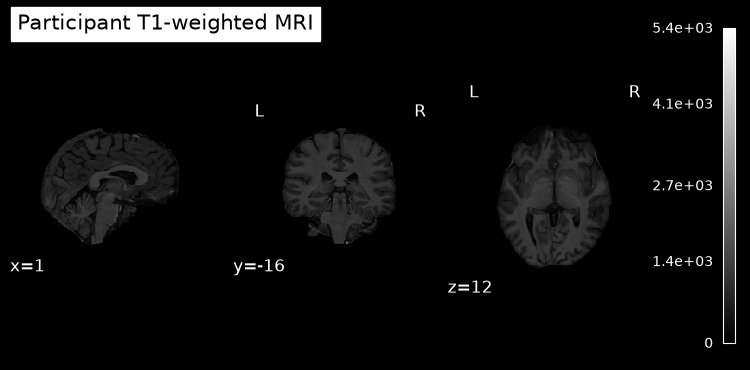

In [8]:

from nilearn import plotting

plotting.plot_anat(
    img,
    title="Participant T1-weighted MRI",
    display_mode="ortho",
    draw_cross=False
)

plt.show()


In [12]:
from pathlib import Path
import nibabel as nib

mni_path = Path(
    r"C:\Users\risha\OneDrive\Documents\MNI152_T1_2009c (2) (1).nii"
)

print("File found:", mni_path.exists())

File found: True


In [13]:
mni_img = nib.load(str(mni_path))

print("MNI template dimensions:", mni_img.shape)
print("Voxel size:", mni_img.header.get_zooms()[:3])
print("Orientation:", nib.aff2axcodes(mni_img.affine))

MNI template dimensions: (193, 229, 193)
Voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Orientation: ('R', 'A', 'S')


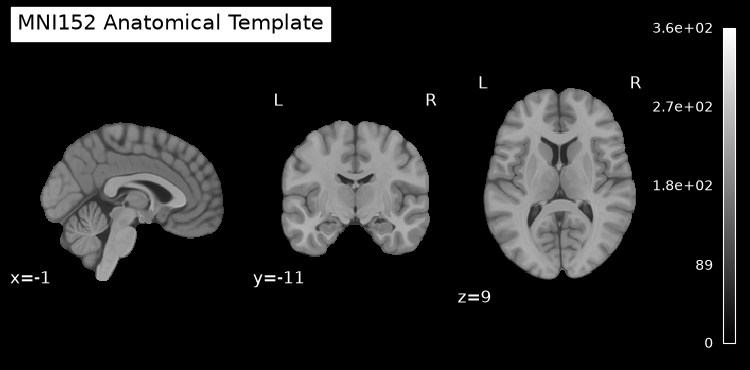

In [14]:
from nilearn import plotting
import matplotlib.pyplot as plt

plotting.plot_anat(
    mni_img,
    title="MNI152 Anatomical Template",
    display_mode="ortho",
    draw_cross=False
)

plt.show()

In [15]:
from nilearn import datasets

ho_atlas = datasets.fetch_atlas_harvard_oxford(
    "sub-maxprob-thr25-1mm",
    symmetric_split=True
)

print("Harvard-Oxford atlas downloaded!")

for index, label in enumerate(ho_atlas.labels):
    if "hippocampus" in label.lower():
        print(index, label)

[fetch_atlas_harvard_oxford] Dataset directory found: C:\Users\risha\nilearn_data\fsl
Harvard-Oxford atlas downloaded!
10 Left Hippocampus
20 Right Hippocampus


In [17]:

import numpy as np
import nibabel as nib

# The Harvard-Oxford atlas is already loaded
atlas_img = ho_atlas.maps

# Extract atlas data
atlas_data = np.asarray(atlas_img.dataobj)

# Identify left and right hippocampus
left_mask = (atlas_data == 10).astype(np.uint8)
right_mask = (atlas_data == 20).astype(np.uint8)

# Combine both hippocampi
bilateral_mask = left_mask + right_mask

# Create NIfTI images
left_img = nib.Nifti1Image(left_mask, atlas_img.affine)
right_img = nib.Nifti1Image(right_mask, atlas_img.affine)
bilateral_img = nib.Nifti1Image(bilateral_mask, atlas_img.affine)

print("Left hippocampus voxels:", left_mask.sum())
print("Right hippocampus voxels:", right_mask.sum())
print("Total hippocampus voxels:", bilateral_mask.sum())
print("Atlas voxel size:", atlas_img.header.get_zooms()[:3])


Left hippocampus voxels: 5575
Right hippocampus voxels: 5688
Total hippocampus voxels: 11263
Atlas voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))


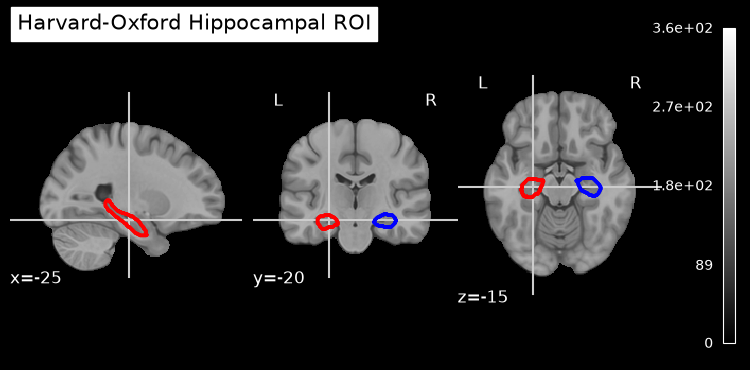

In [18]:

from nilearn import plotting
import matplotlib.pyplot as plt

display = plotting.plot_anat(
    mni_img,
    title="Harvard-Oxford Hippocampal ROI",
    display_mode="ortho",
    cut_coords=(-25, -20, -15)
)

display.add_contours(
    left_img,
    colors="red",
    linewidths=2
)

display.add_contours(
    right_img,
    colors="blue",
    linewidths=2
)

plt.show()


In [19]:

print("MNI template shape:", mni_img.shape)
print("Atlas shape:", atlas_img.shape)

print("MNI orientation:",
      nib.aff2axcodes(mni_img.affine))

print("Atlas orientation:",
      nib.aff2axcodes(atlas_img.affine))

print("Same voxel grid:",
      mni_img.shape == atlas_img.shape
      and np.allclose(mni_img.affine, atlas_img.affine))


MNI template shape: (193, 229, 193)
Atlas shape: (182, 218, 182)
MNI orientation: ('R', 'A', 'S')
Atlas orientation: ('R', 'A', 'S')
Same voxel grid: False


In [20]:

from nilearn.image import resample_to_img
import numpy as np

# Resample hippocampal masks to MNI template grid
left_mni = resample_to_img(
    left_img,
    mni_img,
    interpolation="nearest",
    force_resample=True,
    copy_header=True
)

right_mni = resample_to_img(
    right_img,
    mni_img,
    interpolation="nearest",
    force_resample=True,
    copy_header=True
)

# Verify image dimensions and coordinates
print("MNI template shape:", mni_img.shape)
print("Left mask shape:", left_mni.shape)
print("Right mask shape:", right_mni.shape)

print("Left mask affine matches:",
      np.allclose(left_mni.affine, mni_img.affine))

print("Right mask affine matches:",
      np.allclose(right_mni.affine, mni_img.affine))

print("Left mask voxels:",
      np.count_nonzero(left_mni.get_fdata()))

print("Right mask voxels:",
      np.count_nonzero(right_mni.get_fdata()))


MNI template shape: (193, 229, 193)
Left mask shape: (193, 229, 193)
Right mask shape: (193, 229, 193)
Left mask affine matches: True
Right mask affine matches: True
Left mask voxels: 5575
Right mask voxels: 5688


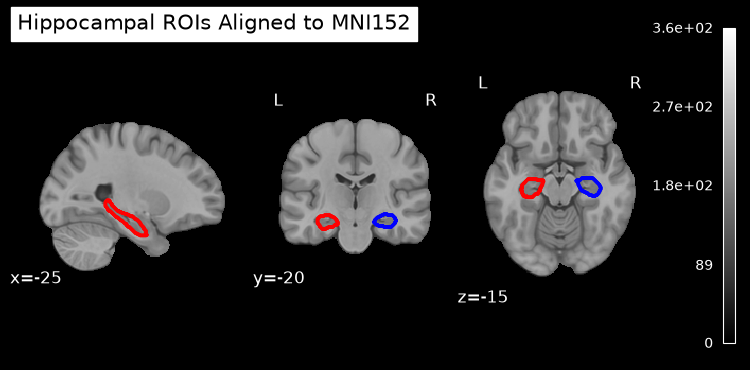

In [21]:

from nilearn import plotting
import matplotlib.pyplot as plt

display = plotting.plot_anat(
    mni_img,
    title="Hippocampal ROIs Aligned to MNI152",
    display_mode="ortho",
    cut_coords=(-25, -20, -15),
    draw_cross=False
)

display.add_contours(
    left_mni,
    colors="red",
    linewidths=2
)

display.add_contours(
    right_mni,
    colors="blue",
    linewidths=2
)

plt.show()


In [22]:

import nibabel as nib
import numpy as np

# Find previously downloaded T1-weighted MRI
local_t1_files = sorted(DATA_DIR.glob("*_T1w.nii.gz"))

print("Local T1 scans found:", len(local_t1_files))

if not local_t1_files:
    raise FileNotFoundError(
        f"No T1-weighted scans found in {DATA_DIR}"
    )

participant_path = local_t1_files[0]
participant_img = nib.load(str(participant_path))

print("Participant file:", participant_path.name)
print("Dimensions:", participant_img.shape)
print("Voxel size:", participant_img.header.get_zooms()[:3])
print("Orientation:", nib.aff2axcodes(participant_img.affine))
print("Voxel volume (mm³):",
      np.prod(participant_img.header.get_zooms()[:3]))


Local T1 scans found: 1
Participant file: sub-01_T1w.nii.gz
Dimensions: (240, 240, 180)
Voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0000153))
Orientation: ('R', 'A', 'S')
Voxel volume (mm³): 1.0000153


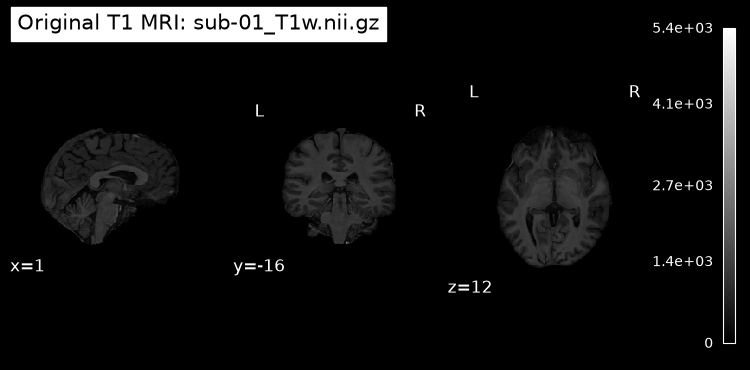

In [23]:

from nilearn import plotting
import matplotlib.pyplot as plt

plotting.plot_anat(
    participant_img,
    title=f"Original T1 MRI: {participant_path.name}",
    display_mode="ortho",
    draw_cross=False
)

plt.show()


Display minimum: 63.03259517669678
Display maximum: 1288.8159460449217


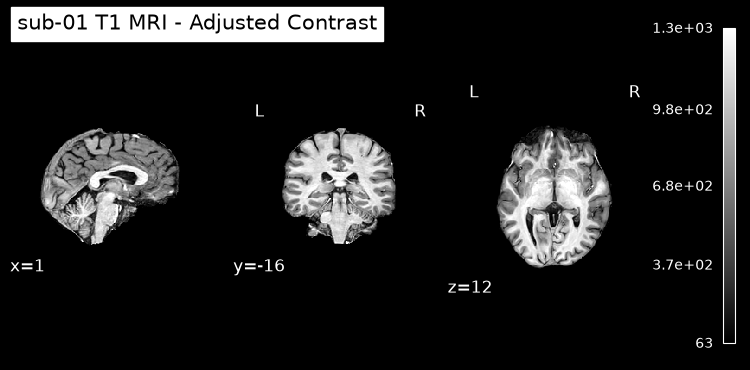

In [24]:

import numpy as np
import matplotlib.pyplot as plt
from nilearn import plotting

# Calculate display intensity limits
data = participant_img.get_fdata()
brain_values = data[data > 0]

vmin = np.percentile(brain_values, 1)
vmax = np.percentile(brain_values, 99)

print("Display minimum:", vmin)
print("Display maximum:", vmax)

plotting.plot_anat(
    participant_img,
    title="sub-01 T1 MRI - Adjusted Contrast",
    display_mode="ortho",
    draw_cross=False,
    vmin=vmin,
    vmax=vmax,
    black_bg=True
)

plt.show()


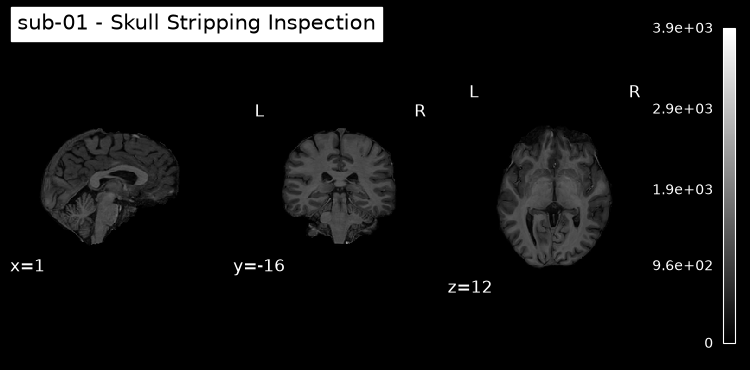

In [25]:

from nilearn import plotting

plotting.plot_anat(
    participant_img,
    title="sub-01 - Skull Stripping Inspection",
    display_mode="ortho",
    draw_cross=False,
    dim=0
)

plt.show()


In [27]:

import SimpleITK as sitk
import numpy as np

print("SimpleITK version:", sitk.Version_VersionString())
print("SimpleITK imported successfully!")


SimpleITK version: 2.5.6
SimpleITK imported successfully!


In [28]:

# Load participant's original MRI
moving_img = sitk.ReadImage(str(participant_path), sitk.sitkFloat32)

# Load MNI152 reference template
fixed_img = sitk.ReadImage(str(mni_path), sitk.sitkFloat32)

print("Participant dimensions:", moving_img.GetSize())
print("MNI dimensions:", fixed_img.GetSize())

print("Participant spacing:", moving_img.GetSpacing())
print("MNI spacing:", fixed_img.GetSpacing())

print("Participant origin:", moving_img.GetOrigin())
print("MNI origin:", fixed_img.GetOrigin())


Participant dimensions: (240, 240, 180)
MNI dimensions: (193, 229, 193)
Participant spacing: (1.0, 1.0, 1.0000152587890625)
MNI spacing: (1.0, 1.0, 1.0)
Participant origin: (117.1963882446289, 118.19267272949219, -55.26200866699219)
MNI origin: (96.0, 132.0, -78.0)


In [29]:

# Initialize rigid registration
initial_transform = sitk.CenteredTransformInitializer(
    fixed_img,
    moving_img,
    sitk.Euler3DTransform(),
    sitk.CenteredTransformInitializerFilter.GEOMETRY
)

print("Initial transform created successfully!")
print(initial_transform)


Initial transform created successfully!
itk::simple::Euler3DTransform
 Euler3DTransform (000002489B934EC0)
   RTTI typeinfo:   class itk::Euler3DTransform<double>
   Reference Count: 1
   Modified Time: 2074
   Debug: Off
   Object Name: 
   Observers: 
     none
   Matrix: 
     1 0 0 
     0 1 0 
     0 0 1 
   Offset: [-3.305, -28.2369, 1.27819]
   Center: [0, 18, 18]
   Translation: [-3.305, -28.2369, 1.27819]
   Inverse: 
     1 0 0 
     0 1 0 
     0 0 1 
   Singular: 0
   AngleX: 0
   AngleY: 0
   AngleZ: 0
   ComputeZYX: Off



In [30]:

registration = sitk.ImageRegistrationMethod()

# Mutual information similarity metric
registration.SetMetricAsMattesMutualInformation(
    numberOfHistogramBins=50
)

registration.SetMetricSamplingStrategy(
    registration.RANDOM
)

registration.SetMetricSamplingPercentage(0.05)

registration.SetInterpolator(sitk.sitkLinear)

# Gradient descent optimizer
registration.SetOptimizerAsRegularStepGradientDescent(
    learningRate=2.0,
    minStep=0.001,
    numberOfIterations=150,
    relaxationFactor=0.5
)

registration.SetOptimizerScalesFromPhysicalShift()

# Multi-resolution registration
registration.SetShrinkFactorsPerLevel([4, 2, 1])
registration.SetSmoothingSigmasPerLevel([2, 1, 0])
registration.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()

registration.SetInitialTransform(
    initial_transform,
    inPlace=False
)

print("Starting rigid registration...")

final_transform = registration.Execute(
    fixed_img,
    moving_img
)

print("Registration completed!")
print("Final metric value:", registration.GetMetricValue())
print("Optimizer stop condition:",
      registration.GetOptimizerStopConditionDescription())


Starting rigid registration...
Registration completed!
Final metric value: -0.3594792013895431
Optimizer stop condition: RegularStepGradientDescentOptimizerv4: Gradient magnitude tolerance met after 17 iterations. Gradient magnitude (4.61465e-05) is less than gradient magnitude tolerance (0.0001).


In [31]:

registered_img = sitk.Resample(
    moving_img,
    fixed_img,
    final_transform,
    sitk.sitkLinear,
    0.0,
    sitk.sitkFloat32
)

registered_path = OUTPUT_DIR / "sub-01_rigid_MNI.nii.gz"

sitk.WriteImage(registered_img, str(registered_path))

print("Registered image saved to:", registered_path)


Registered image saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\sub-01_rigid_MNI.nii.gz


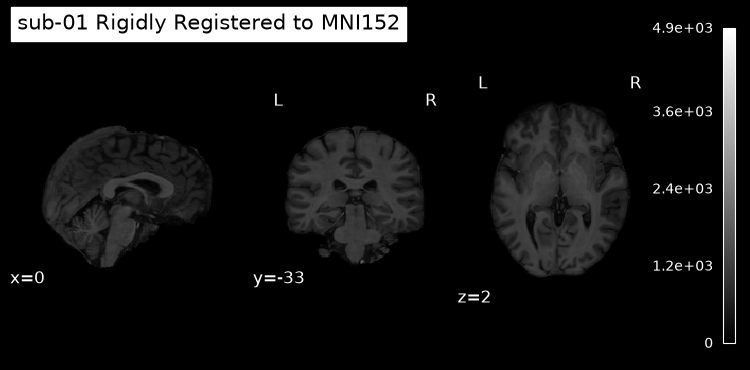

In [32]:

import nibabel as nib
from nilearn import plotting
import matplotlib.pyplot as plt

registered_nib = nib.load(str(registered_path))

plotting.plot_anat(
    registered_nib,
    title="sub-01 Rigidly Registered to MNI152",
    display_mode="ortho",
    draw_cross=False
)

plt.show()


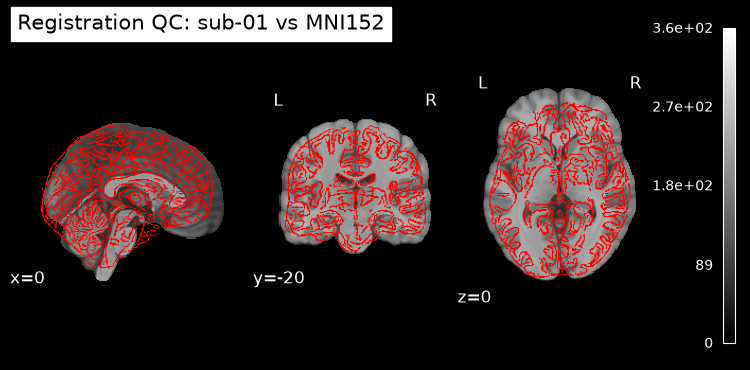

In [33]:

from nilearn import plotting
import matplotlib.pyplot as plt

display = plotting.plot_anat(
    mni_img,
    title="Registration QC: sub-01 vs MNI152",
    display_mode="ortho",
    cut_coords=(0, -20, 0),
    draw_cross=False
)

display.add_edges(
    registered_nib,
    color="red"
)

plt.show()


In [34]:

print("Final transformation:")
print(final_transform)

print("Registered image shape:", registered_nib.shape)
print("MNI template shape:", mni_img.shape)

print(
    "Same voxel grid:",
    registered_nib.shape == mni_img.shape
    and np.allclose(registered_nib.affine, mni_img.affine)
)


Final transformation:
itk::simple::CompositeTransform
 CompositeTransform (000002489AB19400)
   RTTI typeinfo:   class itk::CompositeTransform<double,3>
   Reference Count: 1
   Modified Time: 975636
   Debug: Off
   Object Name: 
   Observers: 
     none
   TransformQueue: 
   >>>>>>>>>
   Euler3DTransform (000002489B930ED0)
     RTTI typeinfo:   class itk::Euler3DTransform<double>
     Reference Count: 1
     Modified Time: 975626
     Debug: Off
     Object Name: 
     Observers: 
       none
     Matrix: 
       0.999911 0.00131625 -0.0133045 
       -0.000558327 0.998385 0.0568115 
       0.0133578 -0.056799 0.998296 
     Offset: [-2.8473, -19.2467, 13.1699]
     Center: [0, 18, 18]
     Translation: [-3.06309, -18.2531, 12.1168]
     Inverse: 
       0.999911 -0.000558327 0.0133578 
       0.00131625 0.998385 -0.056799 
       -0.0133045 0.0568115 0.998296 
     Singular: 0
     AngleX: -0.0568296
     AngleY: -0.0133798
     AngleZ: -0.00131838
     ComputeZYX: Off
   Transform

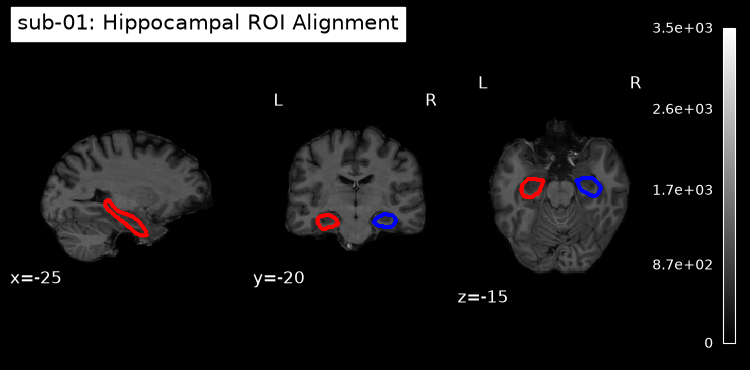

In [35]:

from nilearn import plotting
import matplotlib.pyplot as plt

display = plotting.plot_anat(
    registered_nib,
    title="sub-01: Hippocampal ROI Alignment",
    display_mode="ortho",
    cut_coords=(-25, -20, -15),
    draw_cross=False,
    dim=0
)

display.add_contours(
    left_mni,
    colors="red",
    linewidths=2
)

display.add_contours(
    right_mni,
    colors="blue",
    linewidths=2
)

plt.show()


In [36]:

import SimpleITK as sitk

transform_path = OUTPUT_DIR / "sub-01_rigid_transform.tfm"

sitk.WriteTransform(
    final_transform,
    str(transform_path)
)

print("Transform saved:", transform_path)
print("File exists:", transform_path.exists())


Transform saved: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\sub-01_rigid_transform.tfm
File exists: True


In [37]:

from nilearn import plotting

qc_path = FIGURE_DIR / "sub-01_hippocampal_alignment.png"

display = plotting.plot_anat(
    registered_nib,
    title="sub-01: Hippocampal Atlas Alignment",
    display_mode="ortho",
    cut_coords=(-25, -20, -15),
    draw_cross=False
)

display.add_contours(
    left_mni,
    colors="red",
    linewidths=2
)

display.add_contours(
    right_mni,
    colors="blue",
    linewidths=2
)

display.savefig(str(qc_path))
display.close()

print("Figure saved:", qc_path)
print("File exists:", qc_path.exists())


Figure saved: C:\Users\risha\Documents\NSCI270_Hippocampus\figures\sub-01_hippocampal_alignment.png
File exists: True


In [38]:

import torch
import platform

print("PyTorch version:", torch.__version__)
print("Python architecture:", platform.machine())
print("CUDA available:", torch.cuda.is_available())

# Check whether PyTorch can perform a basic operation
try:
    x = torch.rand(3, 3)
    print("PyTorch test successful!")
    print(x)
except Exception as e:
    print("PyTorch test failed:", e)


PyTorch version: 2.14.1+cpu
Python architecture: ARM64
CUDA available: False
PyTorch test successful!
tensor([[0.0108, 0.2379, 0.9302],
        [0.1574, 0.5314, 0.8044],
        [0.2776, 0.5307, 0.2968]])


In [39]:

import os
import psutil
import torch

memory = psutil.virtual_memory()

print("Total RAM (GB):", round(memory.total / 1e9, 2))
print("Available RAM (GB):", round(memory.available / 1e9, 2))
print("CPU cores:", os.cpu_count())
print("PyTorch working:", torch.rand(2, 2).shape)


Total RAM (GB): 16.76
Available RAM (GB): 1.92
CPU cores: 10
PyTorch working: torch.Size([2, 2])


In [40]:

import sys
import importlib.util

print("Python version:", sys.version.split()[0])

packages = [
    "torch",
    "SimpleITK",
    "nibabel",
    "nilearn",
    "tensorflow",
    "monai",
    "ants"
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")


Python version: 3.14.6
torch: Installed
SimpleITK: Installed
nibabel: Installed
nilearn: Installed
tensorflow: Not installed
monai: Not installed
ants: Not installed


In [41]:

import nibabel as nib
import numpy as np

img = nib.load(str(participant_path))

print("Participant:", participant_path.name)
print("Image shape:", img.shape)
print("Voxel dimensions (mm):", img.header.get_zooms()[:3])
print("Orientation:", nib.aff2axcodes(img.affine))
print("Image loaded successfully!")


Participant: sub-01_T1w.nii.gz
Image shape: (240, 240, 180)
Voxel dimensions (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0000153))
Orientation: ('R', 'A', 'S')
Image loaded successfully!


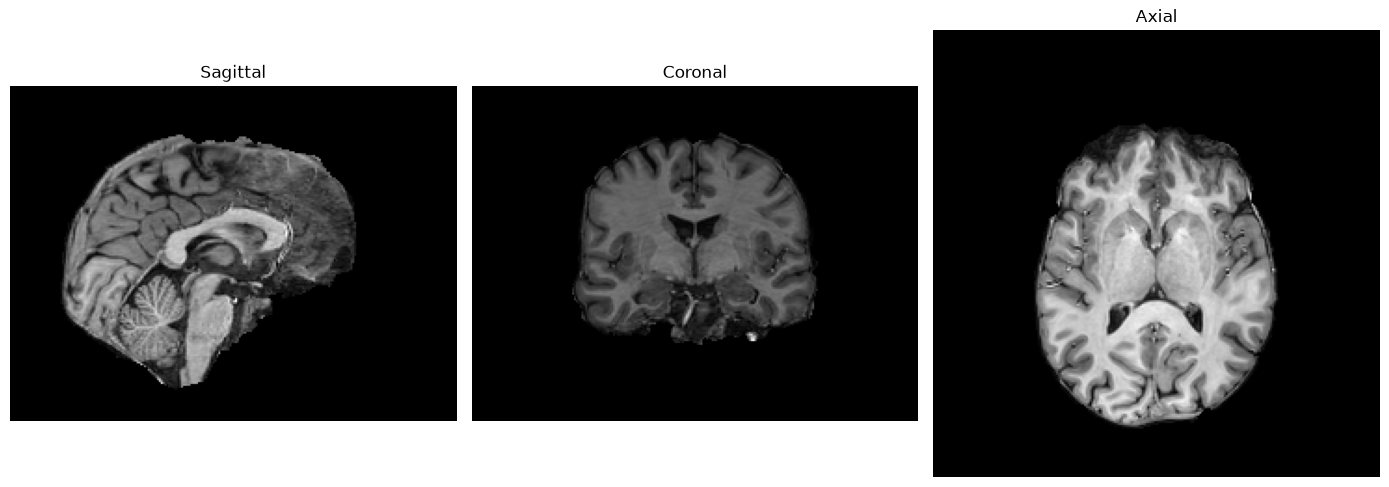

In [42]:

import numpy as np
import matplotlib.pyplot as plt

data = np.asarray(img.dataobj)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

slices = [
    data[120, :, :].T,
    data[:, 120, :].T,
    data[:, :, 90].T
]

titles = ["Sagittal", "Coronal", "Axial"]

for ax, slc, title in zip(axes, slices, titles):
    ax.imshow(slc, cmap="gray", origin="lower")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [43]:

import numpy as np

data = np.asarray(img.dataobj)

positive = data[data > 0]

print("Minimum intensity:", np.min(data))
print("Maximum intensity:", np.max(data))
print("Mean brain intensity:", np.mean(positive))
print("1st percentile:", np.percentile(positive, 1))
print("99th percentile:", np.percentile(positive, 99))
print("NaN values:", np.isnan(data).sum())
print("Infinite values:", np.isinf(data).sum())


Minimum intensity: 0.0
Maximum intensity: 3858.302
Mean brain intensity: 771.797
1st percentile: 63.032597
99th percentile: 1288.8159
NaN values: 0
Infinite values: 0


In [44]:

import subprocess

result = subprocess.run(
    ["conda", "env", "list"],
    capture_output=True,
    text=True
)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)



# conda environments:
#
# * -> active
# + -> frozen
base                 *   C:\Users\risha\anaconda3




In [45]:

import subprocess

result = subprocess.run(
    ["conda", "create", "-n", "hippocampus_seg", "python=3.10", "-y"],
    text=True,
    capture_output=True
)

print("Return code:", result.returncode)
print(result.stdout[-3000:])
print(result.stderr[-3000:])


Return code: 1
Jupyter detected...
3 channel Terms of Service accepted
Retrieving notices: done
Channels:
 - defaults
Platform: win-arm64
Solving environment: failed
Channels:
 - defaults
Platform: win-arm64
Solving environment: failed


PackagesNotFoundInChannelsError: The following packages are not available from current channels:

  - python=3.10

Current channels:

  - defaults

To search for alternate channels that may provide the conda package you're
looking for, navigate to

    https://anaconda.org

and use the search bar at the top of the page.





In [46]:

import subprocess

result = subprocess.run(
    [
        "conda", "create",
        "-n", "hippocampus_seg",
        "-c", "conda-forge",
        "--override-channels",
        "python=3.11",
        "-y"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-2000:])
print(result.stderr[-2000:])


Return code: 1
Jupyter detected...
Retrieving notices: done
Channels:
 - conda-forge
Platform: win-arm64
Solving environment: failed
Channels:
 - conda-forge
Platform: win-arm64
Solving environment: failed


PackagesNotFoundInChannelsError: The following packages are not available from current channels:

  - python=3.11

Current channels:

  - https://conda.anaconda.org/conda-forge

To search for alternate channels that may provide the conda package you're
looking for, navigate to

    https://anaconda.org

and use the search bar at the top of the page.





In [47]:

import numpy as np
import pandas as pd
from nilearn.image import resample_to_img

# Use the registered MRI and atlas masks
brain = np.asarray(registered_nib.dataobj)

left = np.asarray(
    resample_to_img(
        left_mni,
        registered_nib,
        interpolation="nearest",
        force_resample=True,
        copy_header=True
    ).dataobj
) > 0

right = np.asarray(
    resample_to_img(
        right_mni,
        registered_nib,
        interpolation="nearest",
        force_resample=True,
        copy_header=True
    ).dataobj
) > 0

# Extract intensity measurements
results = pd.DataFrame([{
    "participant": "sub-01",
    "left_roi_mean_intensity": float(brain[left].mean()),
    "right_roi_mean_intensity": float(brain[right].mean()),
    "left_roi_std_intensity": float(brain[left].std()),
    "right_roi_std_intensity": float(brain[right].std()),
    "left_atlas_voxels": int(left.sum()),
    "right_atlas_voxels": int(right.sum())
}])

display(results)


TypeError: 'OrthoSlicer' object is not callable

In [48]:
from IPython.display import display

display(results)

,participant,left_roi_mean_intensity,right_roi_mean_intensity,left_roi_std_intensity,right_roi_std_intensity,left_atlas_voxels,right_atlas_voxels
0,sub-01,787.397827,792.070496,186.970917,191.64119,5575,5688


In [49]:

from pathlib import Path

OUTPUT_DIR = Path.home() / "Documents" / "NSCI270_Hippocampus" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

csv_path = OUTPUT_DIR / "hippocampal_roi_preliminary.csv"

results.to_csv(csv_path, index=False)

print("Saved successfully!")
print("File:", csv_path)


Saved successfully!
File: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\hippocampal_roi_preliminary.csv


In [50]:

import SimpleITK as sitk

transform_path = OUTPUT_DIR / "sub-01_rigid_transform.tfm"

sitk.WriteTransform(final_transform, str(transform_path))

print("Registration transform saved:")
print(transform_path)


Registration transform saved:
C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\sub-01_rigid_transform.tfm


In [51]:

import SimpleITK as sitk
import numpy as np

# Load atlas masks in MNI space
left_atlas_sitk = sitk.GetImageFromArray(
    np.asarray(left_mni.dataobj).transpose(2, 1, 0).astype(np.uint8)
)
left_atlas_sitk.CopyInformation(fixed_img)

right_atlas_sitk = sitk.GetImageFromArray(
    np.asarray(right_mni.dataobj).transpose(2, 1, 0).astype(np.uint8)
)
right_atlas_sitk.CopyInformation(fixed_img)

# Convert the MNI-space masks to native participant space
# final_transform maps MNI physical coordinates to participant coordinates
inverse_transform = final_transform.GetInverse()

left_native_sitk = sitk.Resample(
    left_atlas_sitk,
    moving_img,
    inverse_transform,
    sitk.sitkNearestNeighbor,
    0,
    sitk.sitkUInt8
)

right_native_sitk = sitk.Resample(
    right_atlas_sitk,
    moving_img,
    inverse_transform,
    sitk.sitkNearestNeighbor,
    0,
    sitk.sitkUInt8
)

print("Left atlas ROI voxels:", np.count_nonzero(sitk.GetArrayViewFromImage(left_native_sitk)))
print("Right atlas ROI voxels:", np.count_nonzero(sitk.GetArrayViewFromImage(right_native_sitk)))
print("Native image size:", moving_img.GetSize())


Left atlas ROI voxels: 5559
Right atlas ROI voxels: 5695
Native image size: (240, 240, 180)


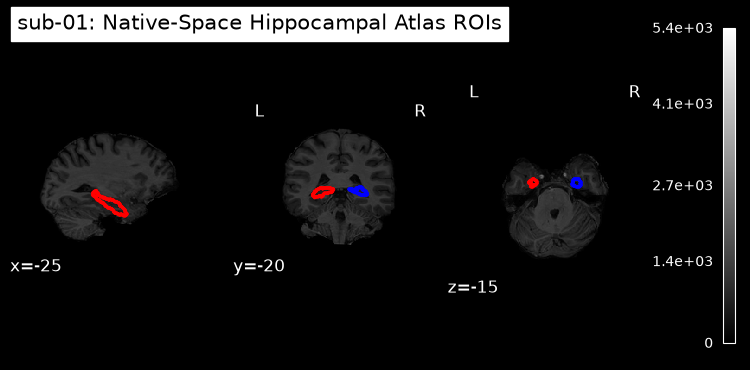

In [52]:

import nibabel as nib
import numpy as np
from nilearn import plotting

# Convert SimpleITK masks into NumPy arrays
left_data = sitk.GetArrayFromImage(left_native_sitk).transpose(2, 1, 0)
right_data = sitk.GetArrayFromImage(right_native_sitk).transpose(2, 1, 0)

# Create NIfTI masks using the original MRI geometry
left_native_img = nib.Nifti1Image(
    left_data.astype(np.uint8),
    img.affine
)

right_native_img = nib.Nifti1Image(
    right_data.astype(np.uint8),
    img.affine
)

# Display atlas ROIs on the original MRI
view = plotting.plot_anat(
    img,
    title="sub-01: Native-Space Hippocampal Atlas ROIs",
    display_mode="ortho",
    cut_coords=(-25, -20, -15),
    draw_cross=False
)

view.add_contours(left_native_img, colors="red", linewidths=2)
view.add_contours(right_native_img, colors="blue", linewidths=2)

plotting.show()


In [53]:

from pathlib import Path
import nibabel as nib

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

left_path = OUTPUT_DIR / "sub-01_left_hippocampus_atlas_roi.nii.gz"
right_path = OUTPUT_DIR / "sub-01_right_hippocampus_atlas_roi.nii.gz"

nib.save(left_native_img, str(left_path))
nib.save(right_native_img, str(right_path))

print("Left atlas ROI saved:", left_path)
print("Right atlas ROI saved:", right_path)


Left atlas ROI saved: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\sub-01_left_hippocampus_atlas_roi.nii.gz
Right atlas ROI saved: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\sub-01_right_hippocampus_atlas_roi.nii.gz


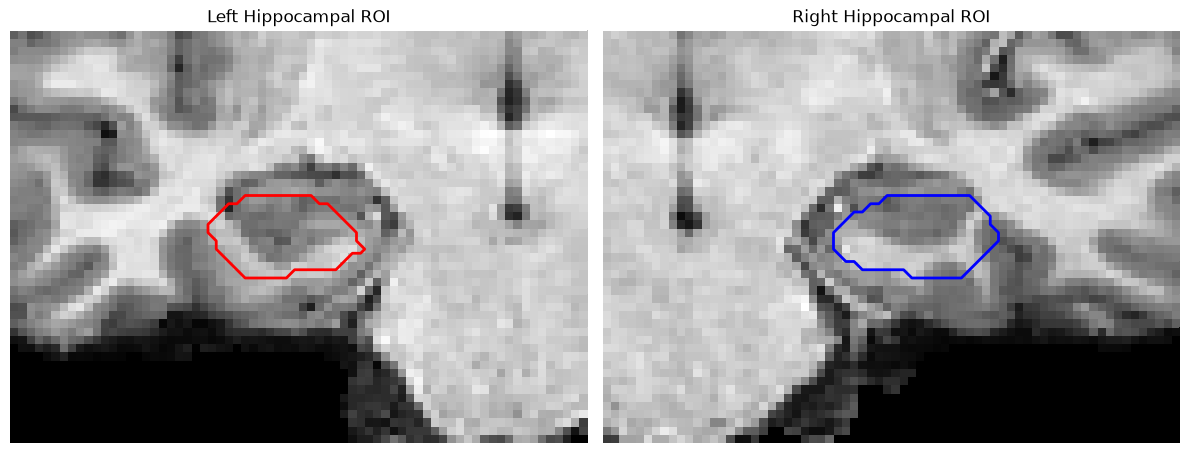

In [54]:

import matplotlib.pyplot as plt
import numpy as np

brain = np.asarray(img.dataobj)
left_mask = np.asarray(left_native_img.dataobj) > 0
right_mask = np.asarray(right_native_img.dataobj) > 0

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, mask, title, color in zip(
    axes,
    [left_mask, right_mask],
    ["Left Hippocampal ROI", "Right Hippocampal ROI"],
    ["red", "blue"]
):
    coords = np.argwhere(mask)
    center = np.round(coords.mean(axis=0)).astype(int)

    # Coronal slice through the ROI center
    y = center[1]
    x_min = max(center[0] - 35, 0)
    x_max = min(center[0] + 35, brain.shape[0])
    z_min = max(center[2] - 25, 0)
    z_max = min(center[2] + 25, brain.shape[2])

    image_slice = brain[x_min:x_max, y, z_min:z_max].T
    mask_slice = mask[x_min:x_max, y, z_min:z_max].T

    ax.imshow(image_slice, cmap="gray", origin="lower")
    ax.contour(mask_slice.astype(float), levels=[0.5],
               colors=[color], linewidths=2)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [55]:

from pathlib import Path

FIGURE_DIR = Path.home() / "Documents" / "NSCI270_Hippocampus" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURE_DIR / "sub-01_hippocampal_roi_QC.png",
    dpi=300,
    bbox_inches="tight"
)

print("Quality-control figure saved successfully!")


Quality-control figure saved successfully!


In [56]:

import numpy as np
import SimpleITK as sitk

# Original MRI data and atlas-derived masks
brain = np.asarray(img.dataobj, dtype=np.float32)
left_seed = np.asarray(left_native_img.dataobj) > 0
right_seed = np.asarray(right_native_img.dataobj) > 0

# Smooth the MRI slightly to reduce noise
brain_sitk = sitk.ReadImage(str(participant_path), sitk.sitkFloat32)

smoothed_sitk = sitk.SmoothingRecursiveGaussian(
    brain_sitk,
    sigma=0.7
)

smoothed = sitk.GetArrayFromImage(smoothed_sitk).transpose(2, 1, 0)

# Use a low-intensity cutoff estimated from the atlas ROI
# This is an exploratory threshold, not a validated tissue classifier
def refine_roi(seed, image):
    values = image[seed]
    threshold = np.percentile(values, 15)

    refined = seed & (image >= threshold)

    return refined, threshold

left_refined, left_threshold = refine_roi(left_seed, smoothed)
right_refined, right_threshold = refine_roi(right_seed, smoothed)

print("Left intensity threshold:", round(float(left_threshold), 2))
print("Right intensity threshold:", round(float(right_threshold), 2))

print("Left refined voxels:", int(left_refined.sum()))
print("Right refined voxels:", int(right_refined.sum()))


Left intensity threshold: 640.44
Right intensity threshold: 642.34
Left refined voxels: 4725
Right refined voxels: 4840


In [57]:

import numpy as np
import pandas as pd

# Calculate exact native-space voxel volume
voxel_volume = np.prod(img.header.get_zooms()[:3])

# Calculate exploratory hippocampal volumes
left_volume = left_refined.sum() * voxel_volume
right_volume = right_refined.sum() * voxel_volume

volume_results = pd.DataFrame([{
    "participant": "sub-01",
    "left_exploratory_volume_mm3": left_volume,
    "right_exploratory_volume_mm3": right_volume,
    "total_exploratory_volume_mm3": left_volume + right_volume
}])

print("Voxel volume (mm³):", round(voxel_volume, 6))
display(volume_results)


Voxel volume (mm³): 1.000015


,participant,left_exploratory_volume_mm3,right_exploratory_volume_mm3,total_exploratory_volume_mm3
0,sub-01,4725.072098,4840.073853,9565.14595


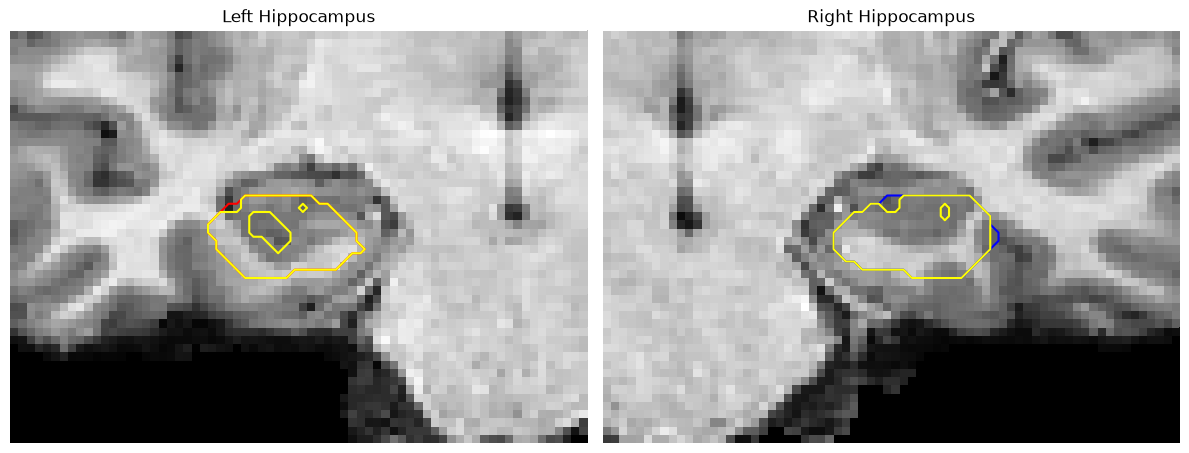

In [58]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, original, refined, title, color in zip(
    axes,
    [left_seed, right_seed],
    [left_refined, right_refined],
    ["Left Hippocampus", "Right Hippocampus"],
    ["red", "blue"]
):
    coords = np.argwhere(original)
    center = np.round(coords.mean(axis=0)).astype(int)

    y = center[1]
    x1, x2 = max(center[0]-35, 0), min(center[0]+35, brain.shape[0])
    z1, z2 = max(center[2]-25, 0), min(center[2]+25, brain.shape[2])

    image_slice = brain[x1:x2, y, z1:z2].T
    original_slice = original[x1:x2, y, z1:z2].T
    refined_slice = refined[x1:x2, y, z1:z2].T

    ax.imshow(image_slice, cmap="gray", origin="lower")
    ax.contour(original_slice, levels=[0.5],
               colors=[color], linewidths=1.5)
    ax.contour(refined_slice, levels=[0.5],
               colors=["yellow"], linewidths=1.5)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [59]:

import numpy as np
from scipy import ndimage

def clean_mask(mask):
    # Fill enclosed holes
    filled = ndimage.binary_fill_holes(mask)

    # Identify connected regions
    labels, num_regions = ndimage.label(filled)

    if num_regions == 0:
        return filled

    # Retain the largest connected region
    sizes = np.bincount(labels.ravel())
    sizes[0] = 0

    largest_region = np.argmax(sizes)

    cleaned = labels == largest_region

    return cleaned

left_cleaned = clean_mask(left_refined)
right_cleaned = clean_mask(right_refined)

print("Left cleaned voxels:", left_cleaned.sum())
print("Right cleaned voxels:", right_cleaned.sum())

print("Left original refined voxels:", left_refined.sum())
print("Right original refined voxels:", right_refined.sum())


Left cleaned voxels: 4726
Right cleaned voxels: 4856
Left original refined voxels: 4725
Right original refined voxels: 4840


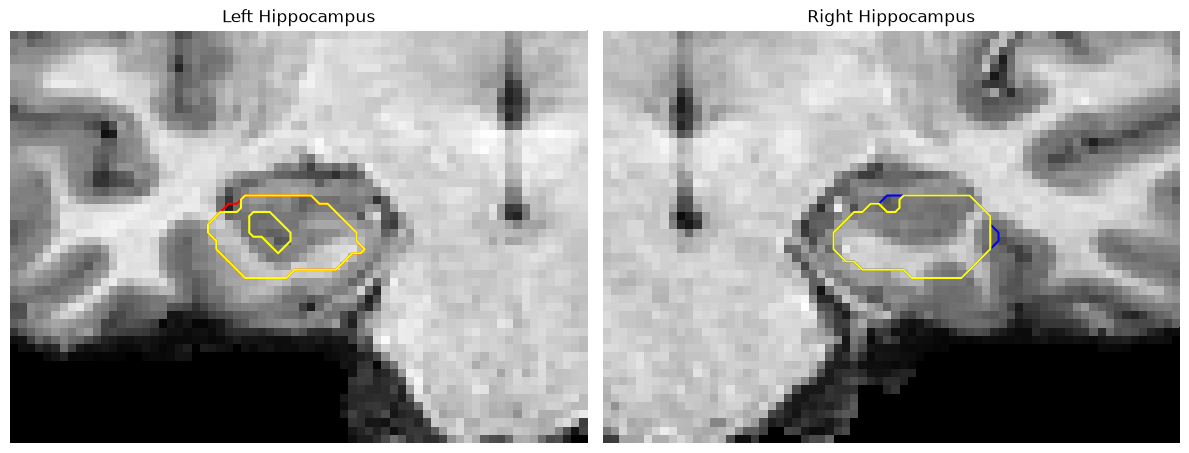

In [60]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, original, cleaned, title, color in zip(
    axes,
    [left_seed, right_seed],
    [left_cleaned, right_cleaned],
    ["Left Hippocampus", "Right Hippocampus"],
    ["red", "blue"]
):
    coords = np.argwhere(original)
    center = np.round(coords.mean(axis=0)).astype(int)

    y = center[1]
    x1, x2 = max(center[0]-35, 0), min(center[0]+35, brain.shape[0])
    z1, z2 = max(center[2]-25, 0), min(center[2]+25, brain.shape[2])

    image_slice = brain[x1:x2, y, z1:z2].T
    original_slice = original[x1:x2, y, z1:z2].T
    cleaned_slice = cleaned[x1:x2, y, z1:z2].T

    ax.imshow(image_slice, cmap="gray", origin="lower")
    ax.contour(original_slice.astype(float), levels=[0.5],
               colors=[color], linewidths=1.5)
    ax.contour(cleaned_slice.astype(float), levels=[0.5],
               colors=["yellow"], linewidths=1.5)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [61]:

import numpy as np
import pandas as pd
from scipy import ndimage

def fill_coronal_holes(mask):
    filled = mask.copy()

    # Fill enclosed holes separately on each coronal slice
    for y in range(mask.shape[1]):
        filled[:, y, :] = ndimage.binary_fill_holes(
            mask[:, y, :]
        )

    return filled

left_filled = fill_coronal_holes(left_cleaned)
right_filled = fill_coronal_holes(right_cleaned)

# Recalculate volumes using the native MRI voxel dimensions
voxel_volume = abs(np.linalg.det(img.affine[:3, :3]))

left_volume_new = left_filled.sum() * voxel_volume
right_volume_new = right_filled.sum() * voxel_volume

updated_results = pd.DataFrame([{
    "participant": "sub-01",
    "left_volume_mm3": left_volume_new,
    "right_volume_mm3": right_volume_new,
    "total_volume_mm3": left_volume_new + right_volume_new
}])

print("Left voxels added:", int(left_filled.sum() - left_cleaned.sum()))
print("Right voxels added:", int(right_filled.sum() - right_cleaned.sum()))

display(updated_results)


Left voxels added: 137
Right voxels added: 60


,participant,left_volume_mm3,right_volume_mm3,total_volume_mm3
0,sub-01,4863.074227,4916.075036,9779.149262


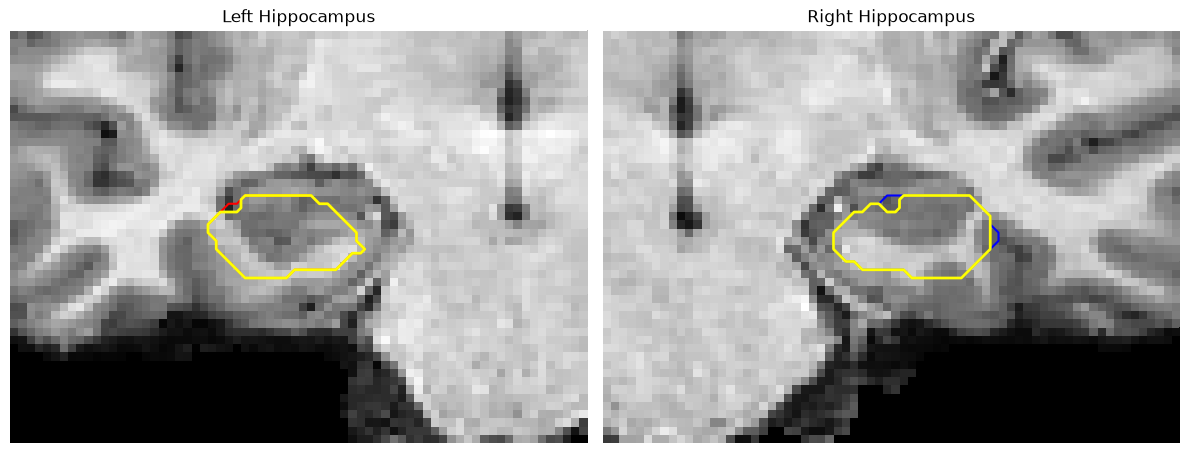

In [62]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, original, filled, title, color in zip(
    axes,
    [left_seed, right_seed],
    [left_filled, right_filled],
    ["Left Hippocampus", "Right Hippocampus"],
    ["red", "blue"]
):
    coords = np.argwhere(original)
    center = np.round(coords.mean(axis=0)).astype(int)

    y = center[1]
    x1, x2 = max(center[0]-35, 0), min(center[0]+35, brain.shape[0])
    z1, z2 = max(center[2]-25, 0), min(center[2]+25, brain.shape[2])

    ax.imshow(
        brain[x1:x2, y, z1:z2].T,
        cmap="gray",
        origin="lower"
    )

    ax.contour(
        original[x1:x2, y, z1:z2].T.astype(float),
        levels=[0.5],
        colors=[color],
        linewidths=1.5
    )

    ax.contour(
        filled[x1:x2, y, z1:z2].T.astype(float),
        levels=[0.5],
        colors=["yellow"],
        linewidths=2
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [63]:

import nibabel as nib
import pandas as pd
import numpy as np

# Save the hole-filled masks
for side, mask in [
    ("left", left_filled),
    ("right", right_filled)
]:
    mask_img = nib.Nifti1Image(
        mask.astype(np.uint8),
        img.affine,
        img.header.copy()
    )

    nib.save(
        mask_img,
        str(OUTPUT_DIR / f"sub-01_{side}_exploratory_filled.nii.gz")
    )

# Save updated exploratory volume estimates
final_results = pd.DataFrame([{
    "participant": "sub-01",
    "left_exploratory_mm3": float(left_volume_new),
    "right_exploratory_mm3": float(right_volume_new),
    "total_exploratory_mm3": float(
        left_volume_new + right_volume_new
    ),
    "method": "Atlas-guided thresholding and 2D hole filling"
}])

csv_path = OUTPUT_DIR / "exploratory_hippocampal_volumes.csv"
final_results.to_csv(csv_path, index=False)

display(final_results)
print("Saved to:", csv_path)


,participant,left_exploratory_mm3,right_exploratory_mm3,total_exploratory_mm3,method
0,sub-01,4863.074227,4916.075036,9779.149262,Atlas-guided thresholding and 2D hole filling


Saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\exploratory_hippocampal_volumes.csv


In [64]:

import gc
import numpy as np
import pandas as pd
import nibabel as nib
import SimpleITK as sitk
from scipy import ndimage
from pathlib import Path

# Confirm OpenNeuro connection and dataset file list
print("Filesystem available:", "fs" in globals())
print("Data directory:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)
print("MNI template:", mni_path)

# Find T1-weighted scans in the OpenNeuro dataset
remote_files = fs.glob(
    "openneuro.org/ds004302/**/anat/*_T1w.nii.gz"
)

print("T1 scans found:", len(remote_files))
print("First three:", remote_files[:3])


Filesystem available: True
Data directory: C:\Users\risha\Documents\NSCI270_Hippocampus\data
Output directory: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs
MNI template: C:\Users\risha\OneDrive\Documents\MNI152_T1_2009c (2) (1).nii
T1 scans found: 71
First three: ['openneuro.org/ds004302/sub-01/anat/sub-01_T1w.nii.gz', 'openneuro.org/ds004302/sub-02/anat/sub-02_T1w.nii.gz', 'openneuro.org/ds004302/sub-03/anat/sub-03_T1w.nii.gz']


In [65]:

import gc
import re
import shutil
import traceback
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib
import SimpleITK as sitk
from scipy import ndimage

OUTPUT_DIR = Path(OUTPUT_DIR)
DATA_DIR = Path(DATA_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

csv_path = OUTPUT_DIR / "exploratory_hippocampal_volumes.csv"
error_path = OUTPUT_DIR / "exploratory_processing_errors.csv"

# Read previously completed results, including sub-01
if csv_path.exists():
    completed = pd.read_csv(csv_path)
else:
    completed = pd.DataFrame()

records = completed.to_dict("records")
done = set(completed["participant"].astype(str)) if not completed.empty else set()

# Use the existing MNI reference and atlas masks
fixed = sitk.ReadImage(str(mni_path), sitk.sitkFloat32)

# Convert nibabel atlas masks to SimpleITK while preserving geometry
def nib_to_sitk_mask(nib_img):
    import tempfile
    with tempfile.TemporaryDirectory() as tmp:
        path = Path(tmp) / "mask.nii.gz"
        nib.save(nib_img, str(path))
        return sitk.ReadImage(str(path), sitk.sitkUInt8)

left_atlas = nib_to_sitk_mask(left_mni)
right_atlas = nib_to_sitk_mask(right_mni)

def clean_and_fill(mask):
    # Match the exploratory processing used for sub-01
    filled = ndimage.binary_fill_holes(mask)

    labels, n = ndimage.label(filled)
    if n > 0:
        sizes = np.bincount(labels.ravel())
        sizes[0] = 0
        filled = labels == np.argmax(sizes)

    result = filled.copy()
    for y in range(result.shape[1]):
        result[:, y, :] = ndimage.binary_fill_holes(
            result[:, y, :]
        )
    return result

def process_participant(remote_path):
    participant = re.search(r"(sub-\d+)", remote_path).group(1)
    local_path = DATA_DIR / f"{participant}_T1w.nii.gz"

    # Download only when necessary
    if not local_path.exists():
        with fs.open(remote_path, "rb") as source:
            with open(local_path, "wb") as destination:
                shutil.copyfileobj(source, destination)

    moving = sitk.ReadImage(str(local_path), sitk.sitkFloat32)

    # Rigid registration: same settings used for sub-01
    initial = sitk.CenteredTransformInitializer(
        fixed,
        moving,
        sitk.Euler3DTransform(),
        sitk.CenteredTransformInitializerFilter.GEOMETRY
    )

    reg = sitk.ImageRegistrationMethod()
    reg.SetMetricAsMattesMutualInformation(50)
    reg.SetMetricSamplingStrategy(reg.RANDOM)
    reg.SetMetricSamplingPercentage(0.05)
    reg.SetInterpolator(sitk.sitkLinear)
    reg.SetOptimizerAsRegularStepGradientDescent(
        learningRate=2.0,
        minStep=0.001,
        numberOfIterations=150,
        relaxationFactor=0.5
    )
    reg.SetOptimizerScalesFromPhysicalShift()
    reg.SetShrinkFactorsPerLevel([4, 2, 1])
    reg.SetSmoothingSigmasPerLevel([2, 1, 0])
    reg.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()
    reg.SetInitialTransform(initial, inPlace=False)

    transform = reg.Execute(fixed, moving)

    # SimpleITK transform maps fixed/MNI to moving/native
    # Resampling atlas onto native grid requires the inverse
    inverse = transform.GetInverse()

    left_native = sitk.Resample(
        left_atlas, moving, inverse,
        sitk.sitkNearestNeighbor, 0, sitk.sitkUInt8
    )
    right_native = sitk.Resample(
        right_atlas, moving, inverse,
        sitk.sitkNearestNeighbor, 0, sitk.sitkUInt8
    )

    # SimpleITK arrays are ordered z, y, x
    left_seed = sitk.GetArrayFromImage(left_native).astype(bool)
    right_seed = sitk.GetArrayFromImage(right_native).astype(bool)

    if not left_seed.any() or not right_seed.any():
        raise ValueError("One or both atlas masks are empty")

    smoothed = sitk.SmoothingRecursiveGaussian(moving, 0.7)
    intensity = sitk.GetArrayFromImage(smoothed)

    def refine(seed):
        threshold = np.percentile(intensity[seed], 15)
        refined = seed & (intensity >= threshold)

        # Convert to x, y, z for the same cleanup
        # and coronal filling used for sub-01
        refined_xyz = refined.transpose(2, 1, 0)
        cleaned_xyz = clean_and_fill(refined_xyz)
        return cleaned_xyz.transpose(2, 1, 0), threshold

    left_final, left_threshold = refine(left_seed)
    right_final, right_threshold = refine(right_seed)

    voxel_volume = float(np.prod(moving.GetSpacing()))

    left_volume = int(left_final.sum()) * voxel_volume
    right_volume = int(right_final.sum()) * voxel_volume

    # Save transform and masks for later quality control
    sitk.WriteTransform(
        transform,
        str(OUTPUT_DIR / f"{participant}_rigid_transform.tfm")
    )

    for side, mask in [
        ("left", left_final),
        ("right", right_final)
    ]:
        mask_image = sitk.GetImageFromArray(
            mask.astype(np.uint8)
        )
        mask_image.CopyInformation(moving)
        sitk.WriteImage(
            mask_image,
            str(OUTPUT_DIR / f"{participant}_{side}_exploratory_filled.nii.gz")
        )

    return {
        "participant": participant,
        "left_exploratory_mm3": left_volume,
        "right_exploratory_mm3": right_volume,
        "total_exploratory_mm3": left_volume + right_volume,
        "left_atlas_voxels": int(left_seed.sum()),
        "right_atlas_voxels": int(right_seed.sum()),
        "left_threshold": float(left_threshold),
        "right_threshold": float(right_threshold),
        "registration_metric": float(reg.GetMetricValue()),
        "method": "Atlas-guided thresholding and 2D hole filling"
    }

errors = []
remaining = [
    p for p in sorted(remote_files)
    if re.search(r"(sub-\d+)", p).group(1) not in done
]

print(f"Already completed: {len(done)}")
print(f"Remaining: {len(remaining)}")

for i, remote_path in enumerate(remaining, 1):
    participant = re.search(r"(sub-\d+)", remote_path).group(1)

    try:
        record = process_participant(remote_path)
        records.append(record)

        # Save immediately after each successful scan
        pd.DataFrame(records).to_csv(csv_path, index=False)

        print(
            f"[{i}/{len(remaining)}] {participant}: "
            f"L={record['left_exploratory_mm3']:.1f}, "
            f"R={record['right_exploratory_mm3']:.1f} mm3"
        )

    except Exception as e:
        errors.append({
            "participant": participant,
            "error": str(e)
        })
        pd.DataFrame(errors).to_csv(error_path, index=False)
        print(f"[{i}/{len(remaining)}] {participant}: ERROR - {e}")

    finally:
        gc.collect()

print("\nProcessing finished.")
print("Successful records:", len(pd.read_csv(csv_path)))
print("Errors:", len(errors))
print("Results:", csv_path)


Already completed: 1
Remaining: 70
[1/70] sub-02: L=4739.0, R=4864.0 mm3
[2/70] sub-03: L=4751.6, R=4813.6 mm3
[3/70] sub-04: L=4922.0, R=5001.0 mm3
[4/70] sub-05: L=4725.0, R=4831.0 mm3
[5/70] sub-06: L=4743.0, R=4854.0 mm3
[6/70] sub-07: L=4725.0, R=4835.0 mm3
[7/70] sub-08: L=4892.9, R=5018.9 mm3
[8/70] sub-09: L=4747.0, R=4858.0 mm3
[9/70] sub-10: L=4754.0, R=4846.0 mm3
[10/70] sub-11: L=4745.0, R=4893.0 mm3
[11/70] sub-12: L=4761.1, R=4869.1 mm3
[12/70] sub-13: L=4763.1, R=4847.1 mm3
[13/70] sub-14: L=4802.2, R=4906.2 mm3
[14/70] sub-15: L=4796.0, R=5102.0 mm3
[15/70] sub-16: L=4846.8, R=4992.8 mm3
[16/70] sub-17: L=4742.9, R=4828.9 mm3
[17/70] sub-18: L=4768.8, R=4973.8 mm3
[18/70] sub-19: L=4712.9, R=4851.9 mm3
[19/70] sub-20: L=4713.5, R=4861.5 mm3
[20/70] sub-21: L=4788.4, R=4894.4 mm3
[21/70] sub-22: L=4805.3, R=4879.3 mm3
[22/70] sub-23: L=4717.9, R=4902.9 mm3
[23/70] sub-24: L=4753.1, R=4901.1 mm3
[24/70] sub-25: L=4711.2, R=4829.2 mm3
[25/70] sub-26: L=4745.0, R=4854.0 mm3

In [66]:

import pandas as pd

csv_path = OUTPUT_DIR / "exploratory_hippocampal_volumes.csv"
df = pd.read_csv(csv_path)

print("Participants:", len(df))
print("Unique participants:", df["participant"].nunique())

print("\nMissing values:")
print(df[[
    "left_exploratory_mm3",
    "right_exploratory_mm3",
    "total_exploratory_mm3"
]].isna().sum())

print("\nVolume summary:")
print(df[[
    "left_exploratory_mm3",
    "right_exploratory_mm3",
    "total_exploratory_mm3"
]].describe().round(2))

print("\nRegistration metric summary:")
print(df["registration_metric"].describe().round(4))


Participants: 71
Unique participants: 71

Missing values:
left_exploratory_mm3     0
right_exploratory_mm3    0
total_exploratory_mm3    0
dtype: int64

Volume summary:
       left_exploratory_mm3  right_exploratory_mm3  total_exploratory_mm3
count                 71.00                  71.00                  71.00
mean                4765.97                4879.87                9645.84
std                   54.00                  59.62                  96.67
min                 4550.90                4797.95                9388.79
25%                 4736.02                4846.56                9589.15
50%                 4754.02                4864.05                9622.44
75%                 4797.55                4890.06                9682.35
max                 4922.00                5102.00                9923.00

Registration metric summary:
count    70.0000
mean     -0.3839
std       0.0484
min      -0.4977
25%      -0.4183
50%      -0.3796
75%      -0.3475
max      -0.2688

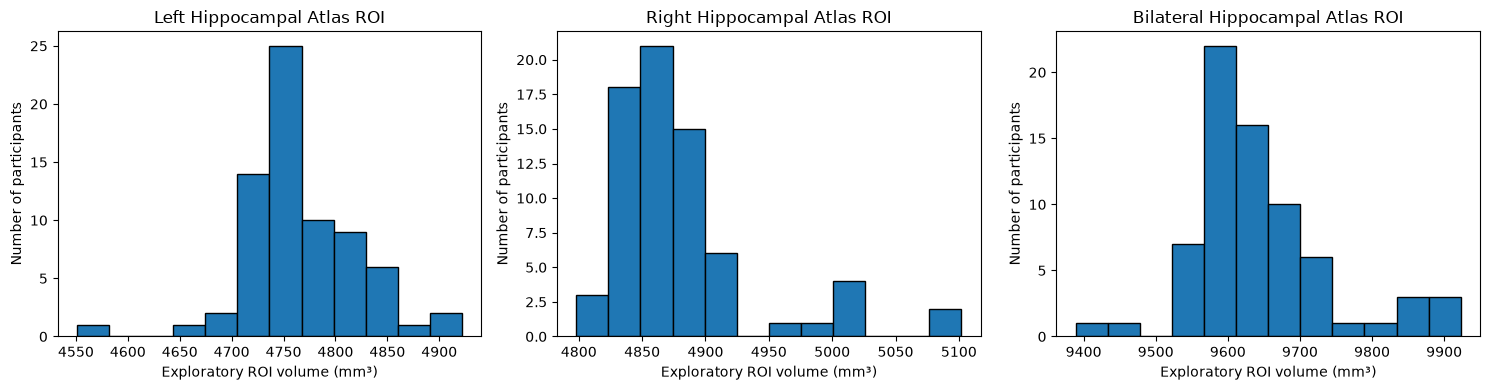

Figure saved: C:\Users\risha\Documents\NSCI270_Hippocampus\figures\exploratory_roi_volume_distributions.png


In [67]:

import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

columns = [
    "left_exploratory_mm3",
    "right_exploratory_mm3",
    "total_exploratory_mm3"
]

titles = [
    "Left Hippocampal Atlas ROI",
    "Right Hippocampal Atlas ROI",
    "Bilateral Hippocampal Atlas ROI"
]

for ax, column, title in zip(axes, columns, titles):
    ax.hist(df[column], bins=12, edgecolor="black")
    ax.set_title(title)
    ax.set_xlabel("Exploratory ROI volume (mm³)")
    ax.set_ylabel("Number of participants")

plt.tight_layout()

figure_path = FIGURE_DIR / "exploratory_roi_volume_distributions.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved:", figure_path)


In [68]:

columns = [
    "left_exploratory_mm3",
    "right_exploratory_mm3",
    "total_exploratory_mm3"
]

for column in columns:
    print(f"\n{column}")
    print("Lowest measurements:")
    print(df.nsmallest(3, column)[["participant", column]].to_string(index=False))

    print("\nHighest measurements:")
    print(df.nlargest(3, column)[["participant", column]].to_string(index=False))



left_exploratory_mm3
Lowest measurements:
participant  left_exploratory_mm3
     sub-36           4550.895836
     sub-71           4667.946579
     sub-27           4696.035828

Highest measurements:
participant  left_exploratory_mm3
     sub-04           4922.000000
     sub-08           4892.925339
     sub-01           4863.074227

right_exploratory_mm3
Lowest measurements:
participant  right_exploratory_mm3
     sub-71            4797.945091
     sub-03            4813.595993
     sub-48            4814.779587

Highest measurements:
participant  right_exploratory_mm3
     sub-15            5102.000000
     sub-58            5080.019379
     sub-75            5024.000000

total_exploratory_mm3
Lowest measurements:
participant  total_exploratory_mm3
     sub-36            9388.785103
     sub-71            9465.891670
     sub-25            9540.400314

Highest measurements:
participant  total_exploratory_mm3
     sub-04            9923.000000
     sub-08            9911.848755
   

In [69]:

import pandas as pd

qc_participants = [
    "sub-36",
    "sub-04",
    "sub-15",
    "sub-58",
    "sub-71"
]

qc_table = df.loc[
    df["participant"].isin(qc_participants),
    [
        "participant",
        "left_exploratory_mm3",
        "right_exploratory_mm3",
        "total_exploratory_mm3",
        "registration_metric"
    ]
].sort_values("participant")

display(qc_table.round(3))


,participant,left_exploratory_mm3,right_exploratory_mm3,total_exploratory_mm3,registration_metric
3,sub-04,4922.000,5001.000,9923.000,-0.421
14,sub-15,4796.000,5102.000,9898.000,-0.396
33,sub-36,4550.896,4837.889,9388.785,-0.296
51,sub-58,4732.018,5080.019,9812.037,-0.448
64,sub-71,4667.947,4797.945,9465.892,-0.375


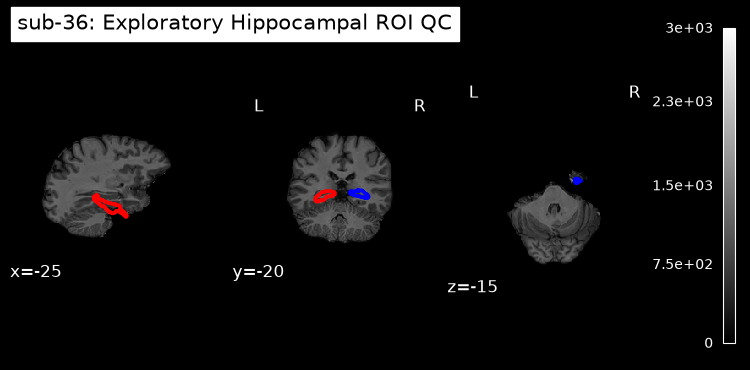

In [70]:

import nibabel as nib
from nilearn import plotting

participant = "sub-36"

brain_path = DATA_DIR / f"{participant}_T1w.nii.gz"
left_path = OUTPUT_DIR / f"{participant}_left_exploratory_filled.nii.gz"
right_path = OUTPUT_DIR / f"{participant}_right_exploratory_filled.nii.gz"

brain_img = nib.load(str(brain_path))
left_img = nib.load(str(left_path))
right_img = nib.load(str(right_path))

view = plotting.plot_anat(
    brain_img,
    title=f"{participant}: Exploratory Hippocampal ROI QC",
    display_mode="ortho",
    cut_coords=(-25, -20, -15),
    draw_cross=False
)

view.add_contours(left_img, colors="red", linewidths=2)
view.add_contours(right_img, colors="blue", linewidths=2)

plotting.show()


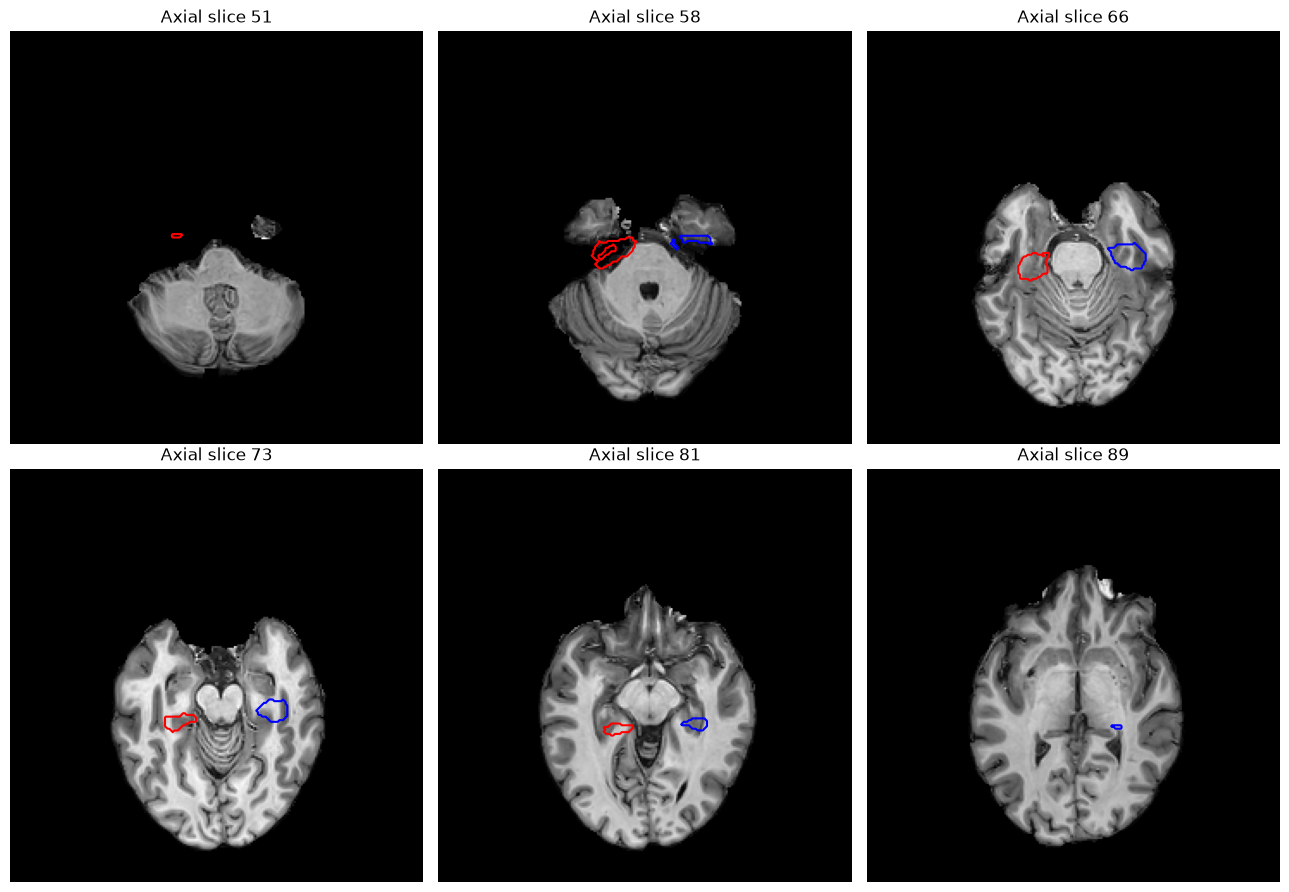

In [71]:

import matplotlib.pyplot as plt
import numpy as np

brain_data = np.asarray(brain_img.dataobj)
left_data = np.asarray(left_img.dataobj) > 0
right_data = np.asarray(right_img.dataobj) > 0

# Select axial slices spanning both hippocampal masks
all_mask = left_data | right_data
z_indices = np.where(all_mask.any(axis=(0, 1)))[0]

slice_indices = np.linspace(
    z_indices.min(),
    z_indices.max(),
    6
).astype(int)

fig, axes = plt.subplots(2, 3, figsize=(13, 9))

for ax, z in zip(axes.flat, slice_indices):
    ax.imshow(
        brain_data[:, :, z].T,
        cmap="gray",
        origin="lower"
    )

    for mask, color in [
        (left_data, "red"),
        (right_data, "blue")
    ]:
        slice_mask = mask[:, :, z].T

        if slice_mask.any():
            ax.contour(
                slice_mask.astype(float),
                levels=[0.5],
                colors=[color],
                linewidths=1.5
            )

    ax.set_title(f"Axial slice {z}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [72]:

import pandas as pd

# Add a quality-control column
if "qc_status" not in df.columns:
    df["qc_status"] = "Not visually reviewed"

# Flag sub-36 without deleting its measurements
df.loc[
    df["participant"] == "sub-36",
    "qc_status"
] = "Flagged: possible atlas misalignment"

# Save a separate QC dataset
qc_csv = OUTPUT_DIR / "exploratory_hippocampal_volumes_QC.csv"
df.to_csv(qc_csv, index=False)

print(df["qc_status"].value_counts())
print("Saved:", qc_csv)


qc_status
Not visually reviewed                   70
Flagged: possible atlas misalignment     1
Name: count, dtype: int64
Saved: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\exploratory_hippocampal_volumes_QC.csv


In [73]:

import pandas as pd

# Keep the original dataset unchanged
df = pd.read_csv(
    OUTPUT_DIR / "exploratory_hippocampal_volumes.csv"
)

# Exclude sub-36 from the analysis dataset
df_analysis = df[
    df["participant"] != "sub-36"
].copy()

# Save the filtered dataset
filtered_path = (
    OUTPUT_DIR / "exploratory_hippocampal_volumes_filtered.csv"
)

df_analysis.to_csv(filtered_path, index=False)

print("Original participants:", len(df))
print("Excluded participant: sub-36")
print("Remaining participants:", len(df_analysis))
print("Saved:", filtered_path)


Original participants: 71
Excluded participant: sub-36
Remaining participants: 70
Saved: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\exploratory_hippocampal_volumes_filtered.csv


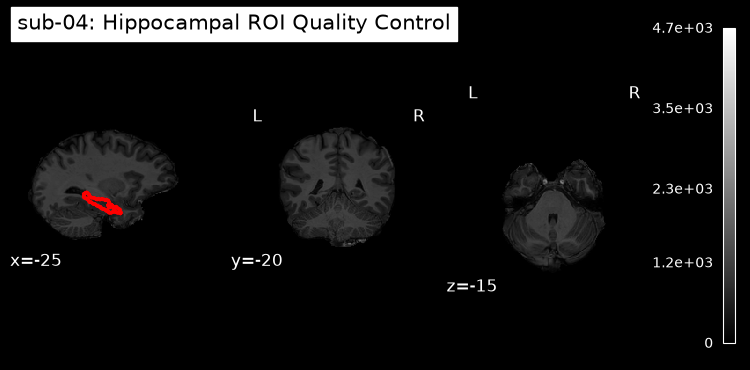

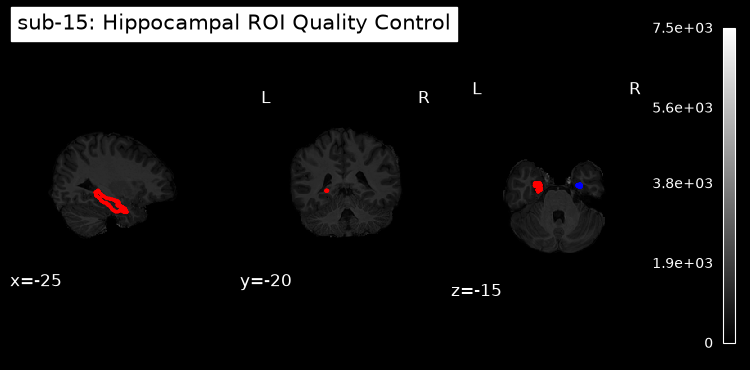

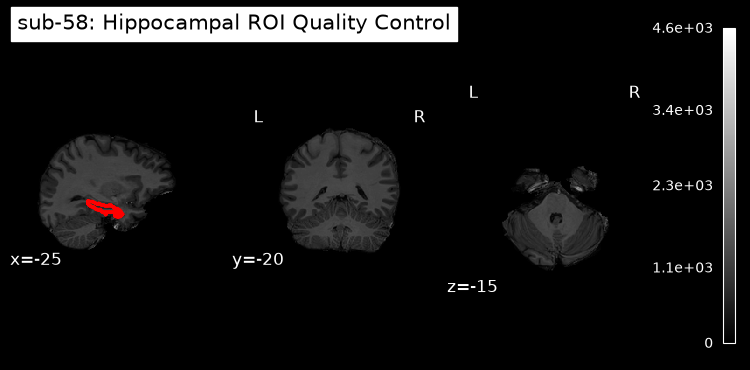

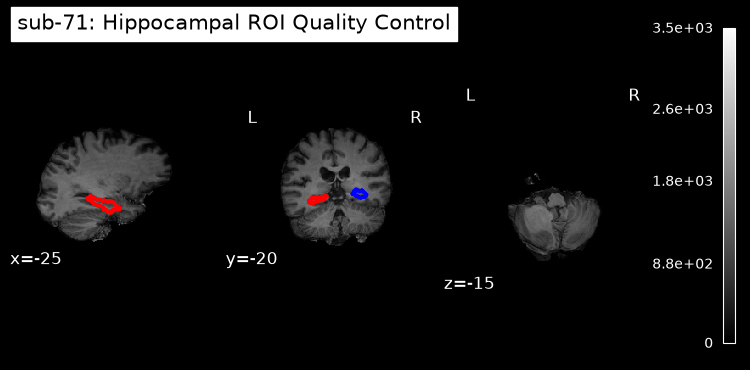

In [74]:

import nibabel as nib
from nilearn import plotting
import matplotlib.pyplot as plt

qc_subjects = ["sub-04", "sub-15", "sub-58", "sub-71"]

for subject in qc_subjects:
    brain_img = nib.load(
        str(DATA_DIR / f"{subject}_T1w.nii.gz")
    )

    left_img = nib.load(
        str(OUTPUT_DIR / f"{subject}_left_exploratory_filled.nii.gz")
    )

    right_img = nib.load(
        str(OUTPUT_DIR / f"{subject}_right_exploratory_filled.nii.gz")
    )

    view = plotting.plot_anat(
        brain_img,
        title=f"{subject}: Hippocampal ROI Quality Control",
        display_mode="ortho",
        cut_coords=(-25, -20, -15),
        draw_cross=False
    )

    view.add_contours(left_img, colors="red", linewidths=2)
    view.add_contours(right_img, colors="blue", linewidths=2)

    plotting.show()


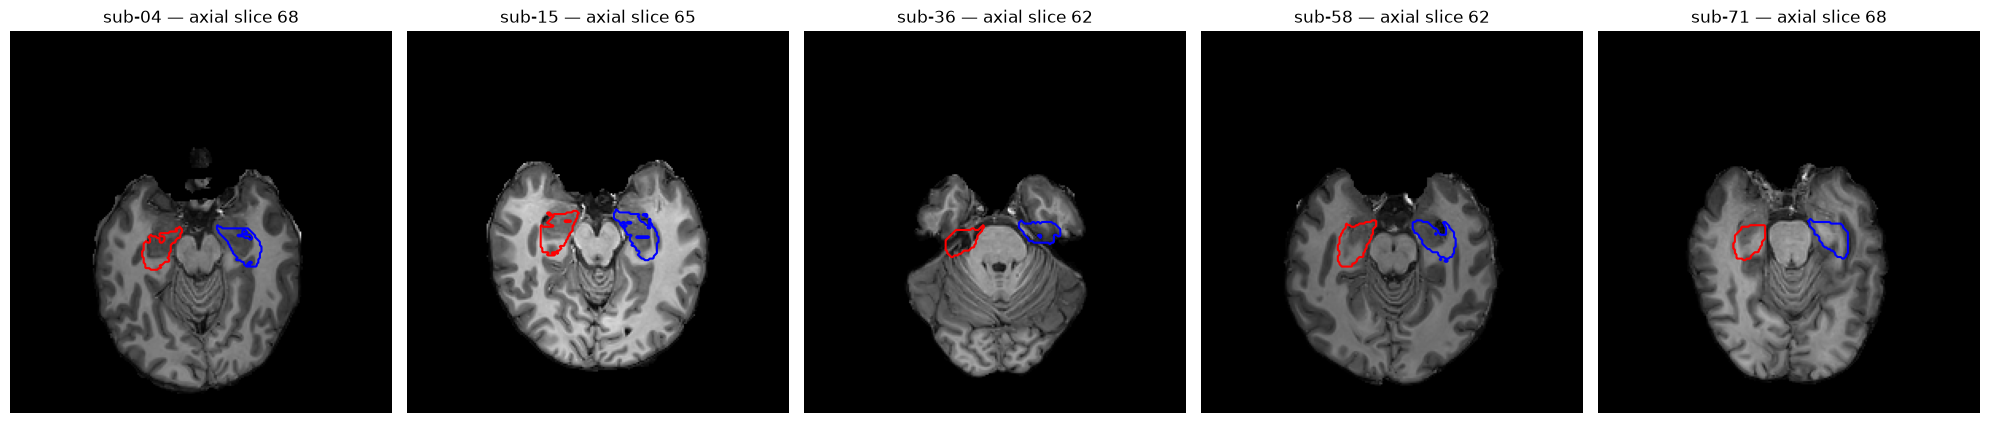

In [75]:

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

subjects = ["sub-04", "sub-15", "sub-36", "sub-58", "sub-71"]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, subject in zip(axes, subjects):
    brain_img = nib.load(str(DATA_DIR / f"{subject}_T1w.nii.gz"))
    brain = np.asarray(brain_img.dataobj)

    left_img = nib.load(
        str(OUTPUT_DIR / f"{subject}_left_exploratory_filled.nii.gz")
    )
    right_img = nib.load(
        str(OUTPUT_DIR / f"{subject}_right_exploratory_filled.nii.gz")
    )

    left = np.asarray(left_img.dataobj) > 0
    right = np.asarray(right_img.dataobj) > 0

    # Find the axial slice containing the most hippocampal mask voxels
    combined = left | right
    z = np.argmax(combined.sum(axis=(0, 1)))

    ax.imshow(brain[:, :, z].T, cmap="gray", origin="lower")

    for mask, color in [(left, "red"), (right, "blue")]:
        if mask[:, :, z].any():
            ax.contour(
                mask[:, :, z].T.astype(float),
                levels=[0.5],
                colors=[color],
                linewidths=1.5
            )

    ax.set_title(f"{subject} — axial slice {z}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [76]:

import pandas as pd

df_qc = pd.read_csv(
    OUTPUT_DIR / "exploratory_hippocampal_volumes.csv"
)

df_qc["qc_status"] = "Not fully reviewed"

df_qc.loc[
    df_qc["participant"].isin(
        ["sub-04", "sub-15", "sub-58", "sub-71"]
    ),
    "qc_status"
] = "Provisional retain - axial QC reviewed"

df_qc.loc[
    df_qc["participant"] == "sub-36",
    "qc_status"
] = "Provisional exclusion - possible misalignment"

df_qc.to_csv(
    OUTPUT_DIR / "exploratory_hippocampal_volumes_QC.csv",
    index=False
)

df_analysis = df_qc[
    df_qc["participant"] != "sub-36"
].copy()

print("Original participants:", len(df_qc))
print("Exploratory analysis participants:", len(df_analysis))
print(df_qc["qc_status"].value_counts())


Original participants: 71
Exploratory analysis participants: 70
qc_status
Not fully reviewed                               66
Provisional retain - axial QC reviewed            4
Provisional exclusion - possible misalignment     1
Name: count, dtype: int64


In [78]:

import pandas as pd
from io import BytesIO

# Download the original participant metadata
metadata_path = "openneuro.org/ds004302/participants.tsv"

with fs.open(metadata_path, "rb") as f:
    participants = pd.read_csv(
        BytesIO(f.read()),
        sep="\t"
    )

print("Metadata shape:", participants.shape)
print("\nColumn names:")
print(participants.columns.tolist())

print("\nFirst five participants:")
display(participants.head())


Metadata shape: (71, 6)

Column names:
['participant_id', 'age', 'sex', 'iq', 'group', 'psyrats']

First five participants:


,participant_id,age,sex,iq,group,psyrats
0,sub-01,47,male,81.0,HC,NaN
1,sub-02,36,male,104.0,HC,NaN
2,sub-03,43,male,108.0,HC,NaN
3,sub-04,25,male,106.0,HC,NaN
4,sub-05,52,female,102.0,HC,NaN


In [79]:

import pandas as pd

# Merge the 70-participant analysis dataset with metadata
df_merged = df_analysis.merge(
    participants[
        ["participant_id", "age", "sex", "iq", "group", "psyrats"]
    ],
    left_on="participant",
    right_on="participant_id",
    how="left",
    validate="one_to_one"
)

# Verify successful matching
print("Total participants:", len(df_merged))

print("\nParticipants per group:")
print(df_merged["group"].value_counts(dropna=False))

print("\nMissing group labels:")
print(df_merged["group"].isna().sum())

print("\nFirst five rows:")
display(df_merged[
    [
        "participant",
        "group",
        "age",
        "sex",
        "left_exploratory_mm3",
        "right_exploratory_mm3",
        "total_exploratory_mm3"
    ]
].head())

# Save the merged dataset
merged_path = (
    OUTPUT_DIR / "exploratory_hippocampal_volumes_with_groups.csv"
)

df_merged.to_csv(merged_path, index=False)

print("\nSaved:", merged_path)


Total participants: 70

Participants per group:
group
HC      25
AVH+    23
AVH-    22
Name: count, dtype: int64

Missing group labels:
0

First five rows:


,participant,group,age,sex,left_exploratory_mm3,right_exploratory_mm3,total_exploratory_mm3
0,sub-01,HC,47,male,4863.074227,4916.075036,9779.149262
1,sub-02,HC,36,male,4739.045195,4864.046387,9603.091581
2,sub-03,HC,43,male,4751.601196,4813.595993,9565.197189
3,sub-04,HC,25,male,4922.000000,5001.000000,9923.000000
4,sub-05,HC,52,female,4725.009012,4831.009214,9556.018227



Saved: C:\Users\risha\Documents\NSCI270_Hippocampus\outputs\exploratory_hippocampal_volumes_with_groups.csv


In [80]:

import pandas as pd

# Exclude sub-36
df_analysis = df[
    df["participant"] != "sub-36"
].copy()

# Merge with participant metadata
df_merged = df_analysis.merge(
    participants[
        ["participant_id", "age", "sex", "iq", "group", "psyrats"]
    ],
    left_on="participant",
    right_on="participant_id",
    how="left",
    validate="one_to_one"
)

print("Total participants:", len(df_merged))

print("\nParticipants per group:")
print(df_merged["group"].value_counts(dropna=False))

print("\nMissing group labels:")
print(df_merged["group"].isna().sum())

# Save the 70-participant dataset
df_merged.to_csv(
    OUTPUT_DIR / "exploratory_hippocampal_volumes_with_groups.csv",
    index=False
)

display(df_merged.head())


Total participants: 70

Participants per group:
group
HC      25
AVH+    23
AVH-    22
Name: count, dtype: int64

Missing group labels:
0


,participant,left_exploratory_mm3,right_exploratory_mm3,total_exploratory_mm3,method,left_atlas_voxels,right_atlas_voxels,left_threshold,right_threshold,registration_metric,participant_id,age,sex,iq,group,psyrats
0,sub-01,4863.074227,4916.075036,9779.149262,Atlas-guided thresholding and 2D hole filling,NaN,NaN,NaN,NaN,NaN,sub-01,47,male,81.0,HC,NaN
1,sub-02,4739.045195,4864.046387,9603.091581,Atlas-guided thresholding and 2D hole filling,5564.0,5681.0,603.317688,640.468079,-0.443094,sub-02,36,male,104.0,HC,NaN
2,sub-03,4751.601196,4813.595993,9565.197189,Atlas-guided thresholding and 2D hole filling,5571.0,5680.0,503.135010,592.423157,-0.379970,sub-03,43,male,108.0,HC,NaN
3,sub-04,4922.000000,5001.000000,9923.000000,Atlas-guided thresholding and 2D hole filling,5563.0,5693.0,591.704163,578.483093,-0.420582,sub-04,25,male,106.0,HC,NaN
4,sub-05,4725.009012,4831.009214,9556.018227,Atlas-guided thresholding and 2D hole filling,5574.0,5687.0,563.914185,555.941650,-0.432839,sub-05,52,female,102.0,HC,NaN


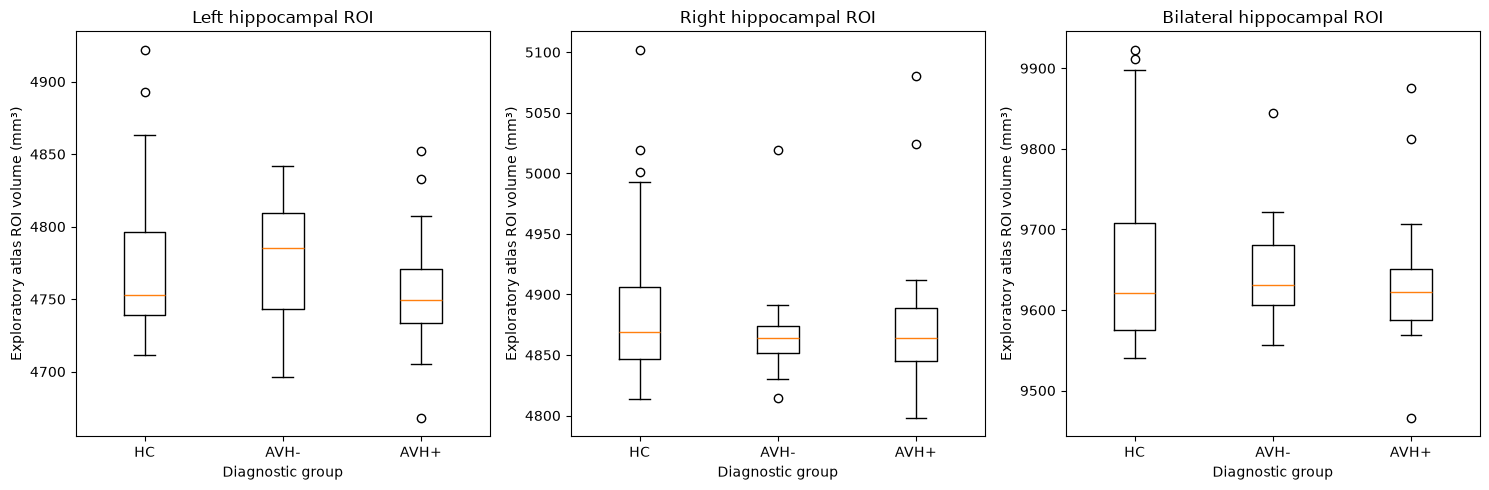

Saved: C:\Users\risha\Documents\NSCI270_Hippocampus\figures\exploratory_group_comparison.png


In [81]:

import matplotlib.pyplot as plt

group_order = ["HC", "AVH-", "AVH+"]
measures = [
    ("left_exploratory_mm3", "Left hippocampal ROI"),
    ("right_exploratory_mm3", "Right hippocampal ROI"),
    ("total_exploratory_mm3", "Bilateral hippocampal ROI")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (column, title) in zip(axes, measures):
    data = [
        df_merged.loc[
            df_merged["group"] == group, column
        ].dropna().values
        for group in group_order
    ]

    ax.boxplot(data, tick_labels=group_order)
    ax.set_title(title)
    ax.set_xlabel("Diagnostic group")
    ax.set_ylabel("Exploratory atlas ROI volume (mm³)")

plt.tight_layout()

figure_path = FIGURE_DIR / "exploratory_group_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", figure_path)


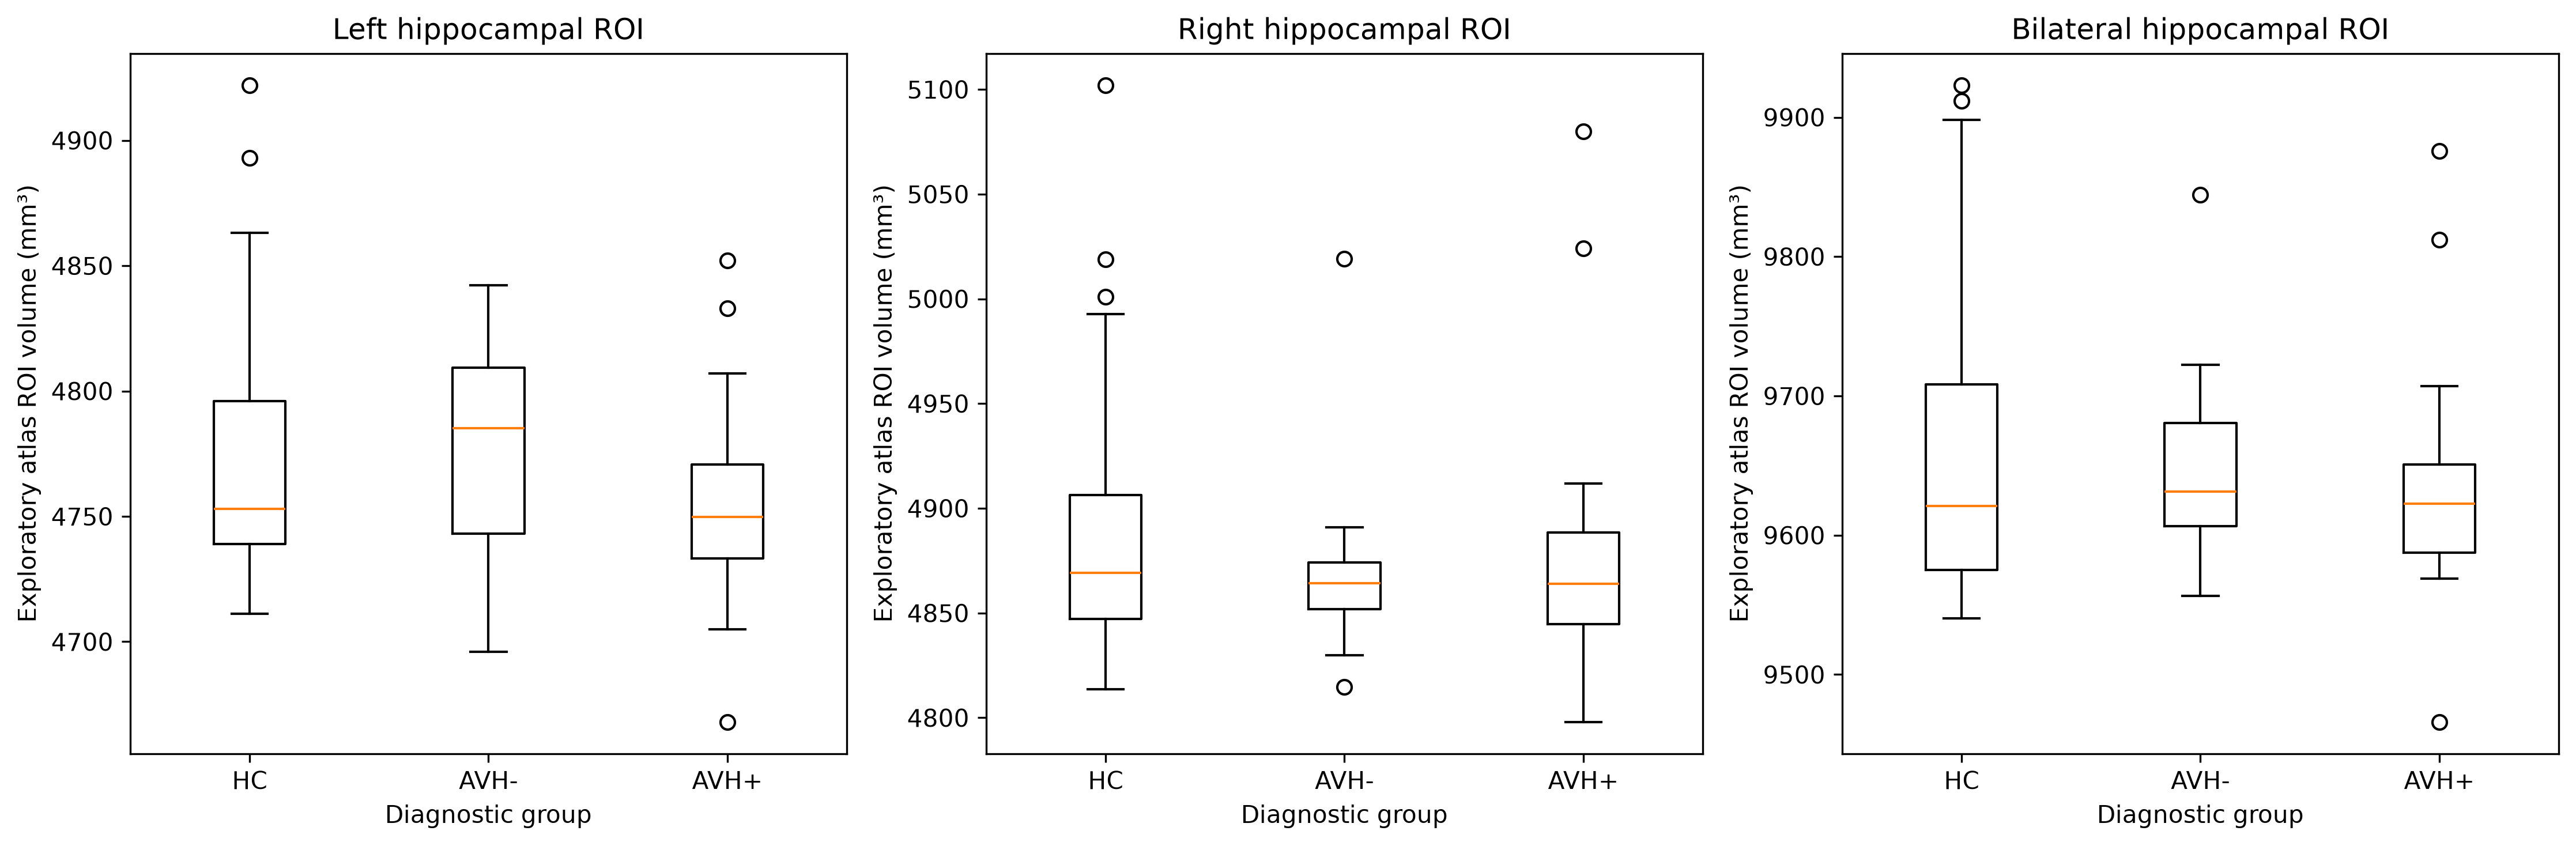

In [82]:
from IPython.display import Image, display

display(Image(filename=str(figure_path)))

In [84]:
from pathlib import Path
import os

print("Figure folder:", FIGURE_DIR)
print("Folder exists:", FIGURE_DIR.exists())
print("Image exists:", figure_path.exists())

# Open the exact folder where the image was saved
if figure_path.exists():
    os.startfile(str(figure_path.parent))

Figure folder: C:\Users\risha\Documents\NSCI270_Hippocampus\figures
Folder exists: True
Image exists: True


In [85]:

columns = [
    "left_exploratory_mm3",
    "right_exploratory_mm3",
    "total_exploratory_mm3"
]

group_stats = (
    df_merged
    .groupby("group")[columns]
    .agg(["count", "mean", "std", "median"])
    .round(2)
    .reindex(["HC", "AVH-", "AVH+"])
)

display(group_stats)

# Save the descriptive statistics
group_stats.to_csv(
    OUTPUT_DIR / "exploratory_group_descriptive_statistics.csv"
)


left_exploratory_mm3                          right_exploratory_mm3  \
                     count     mean    std   median                 count   
group                                                                       
HC                      25  4771.63  56.73  4753.07                    25   
AVH-                    22  4780.24  41.72  4785.21                    22   
AVH+                    23  4755.52  40.59  4749.73                    23   

                               total_exploratory_mm3                            
          mean    std   median                 count     mean     std   median  
group                                                                           
HC     4894.83  71.15  4869.10                    25  9666.47  117.67  9620.82  
AVH-   4866.46  39.31  4864.31                    22  9646.70   66.06  9631.26  
AVH+   4878.26  61.61  4863.93                    23  9633.78   82.62  9622.44

In [86]:

# Age statistics by diagnostic group
age_stats = (
    df_merged
    .groupby("group")["age"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(2)
    .reindex(["HC", "AVH-", "AVH+"])
)

print("AGE DISTRIBUTION")
display(age_stats)

# Sex distribution by diagnostic group
sex_stats = pd.crosstab(
    df_merged["group"],
    df_merged["sex"]
).reindex(["HC", "AVH-", "AVH+"])

print("\nSEX DISTRIBUTION")
display(sex_stats)

# Check missing covariates
print("\nMissing age values:", df_merged["age"].isna().sum())
print("Missing sex values:", df_merged["sex"].isna().sum())


AGE DISTRIBUTION


,count,mean,std,min,max
group,,,,,
HC,25,39.80,14.08,20,64
AVH-,22,44.68,7.43,31,61
AVH+,23,40.09,12.96,19,66



SEX DISTRIBUTION


sex,female,male
group,,
HC,7,18
AVH-,6,16
AVH+,3,20



Missing age values: 0
Missing sex values: 0


In [87]:

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

outcomes = {
    "Left ROI": "left_exploratory_mm3",
    "Right ROI": "right_exploratory_mm3",
    "Bilateral ROI": "total_exploratory_mm3"
}

for label, outcome in outcomes.items():

    model = smf.ols(
        f"{outcome} ~ C(group) + age + C(sex)",
        data=df_merged
    ).fit()

    results = anova_lm(model, typ=2)

    print(f"\n{label} — Exploratory ANCOVA")
    display(results.round(4))



Left ROI — Exploratory ANCOVA


,sum_sq,df,F,PR(>F)
C(group),11499.6962,2.0,2.8145,0.0673
C(sex),3335.1695,1.0,1.6325,0.2059
age,13350.3405,1.0,6.5348,0.0129
Residual,132793.0241,65.0,NaN,NaN



Right ROI — Exploratory ANCOVA


,sum_sq,df,F,PR(>F)
C(group),4555.9973,2.0,0.8101,0.4492
C(sex),746.3751,1.0,0.2654,0.6082
age,53305.8716,1.0,18.9576,0.0000
Residual,182769.6223,65.0,NaN,NaN



Bilateral ROI — Exploratory ANCOVA


,sum_sq,df,F,PR(>F)
C(group),17486.9679,2.0,1.2794,0.2851
C(sex),7237.0398,1.0,1.0590,0.3073
age,120009.8077,1.0,17.5607,0.0001
Residual,444211.1742,65.0,NaN,NaN


In [88]:

import statsmodels.formula.api as smf

for label, outcome in outcomes.items():

    model = smf.ols(
        f"{outcome} ~ C(group) + age + C(sex)",
        data=df_merged
    ).fit()

    print(f"\n{label}")
    print("Age coefficient:", round(model.params["age"], 3))
    print("Age p-value:", round(model.pvalues["age"], 6))
    print("Model R²:", round(model.rsquared, 4))



Left ROI
Age coefficient: -1.179
Age p-value: 0.012924
Model R²: 0.1552

Right ROI
Age coefficient: -2.356
Age p-value: 4.8e-05
Model R²: 0.2601

Bilateral ROI
Age coefficient: -3.535
Age p-value: 8.6e-05
Model R²: 0.2435


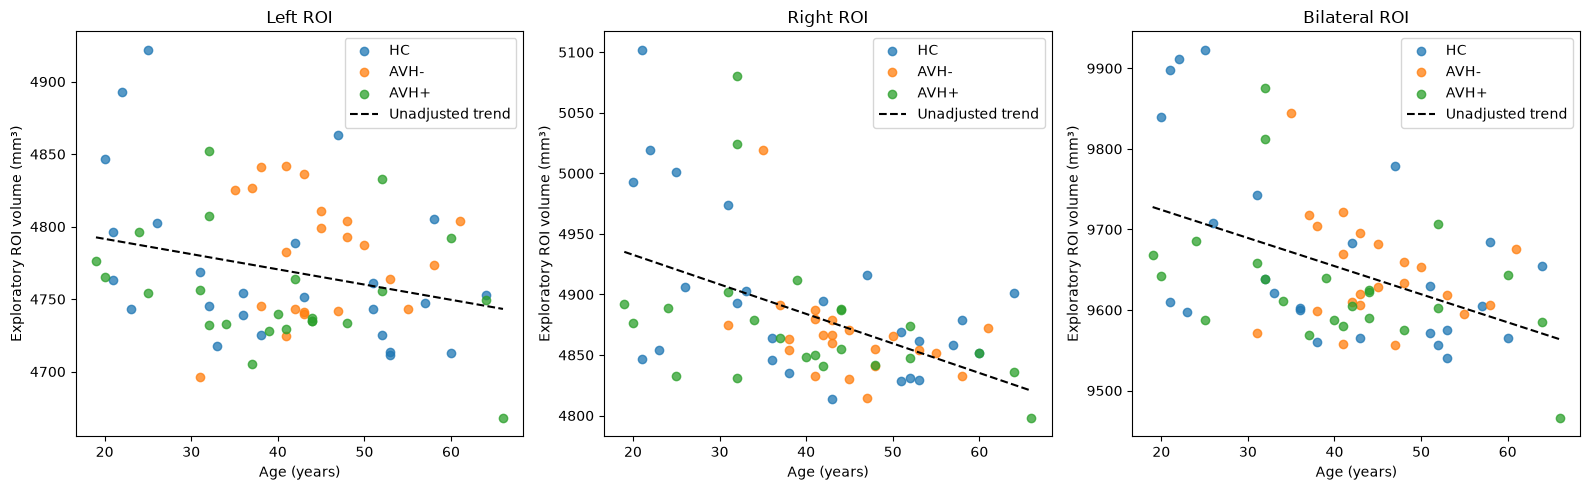

Saved: C:\Users\risha\Documents\NSCI270_Hippocampus\figures\exploratory_age_associations.png


In [89]:

import matplotlib.pyplot as plt
import numpy as np

outcomes = {
    "Left ROI": "left_exploratory_mm3",
    "Right ROI": "right_exploratory_mm3",
    "Bilateral ROI": "total_exploratory_mm3"
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (label, outcome) in zip(axes, outcomes.items()):

    # Plot each diagnostic group separately
    for group in ["HC", "AVH-", "AVH+"]:
        subset = df_merged[df_merged["group"] == group]

        ax.scatter(
            subset["age"],
            subset[outcome],
            label=group,
            alpha=0.75
        )

    # Calculate unadjusted linear regression
    x = df_merged["age"].to_numpy()
    y = df_merged[outcome].to_numpy()

    slope, intercept = np.polyfit(x, y, 1)
    x_line = np.linspace(x.min(), x.max(), 100)

    ax.plot(
        x_line,
        slope * x_line + intercept,
        color="black",
        linestyle="--",
        label="Unadjusted trend"
    )

    ax.set_title(label)
    ax.set_xlabel("Age (years)")
    ax.set_ylabel("Exploratory ROI volume (mm³)")
    ax.legend()

plt.tight_layout()

# Save the figure
figure_path = FIGURE_DIR / "exploratory_age_associations.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Saved:", figure_path)


In [90]:

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import shapiro, levene

outcomes = {
    "Left ROI": "left_exploratory_mm3",
    "Right ROI": "right_exploratory_mm3",
    "Bilateral ROI": "total_exploratory_mm3"
}

results = []

for label, outcome in outcomes.items():

    model = smf.ols(
        f"{outcome} ~ C(group) + age + C(sex)",
        data=df_merged
    ).fit()

    # Normality of model residuals
    shapiro_p = shapiro(model.resid).pvalue

    # Exploratory variance comparison across groups
    group_values = [
        df_merged.loc[
            df_merged["group"] == group, outcome
        ].dropna()
        for group in ["HC", "AVH-", "AVH+"]
    ]

    levene_p = levene(
        *group_values,
        center="median"
    ).pvalue

    # Influence diagnostics
    influence = model.get_influence()
    cooks_d = influence.cooks_distance[0]

    results.append({
        "ROI": label,
        "Shapiro p": shapiro_p,
        "Levene p": levene_p,
        "Max Cook's D": np.max(cooks_d),
        "Participants above 4/n": np.sum(
            cooks_d > 4 / len(df_merged)
        )
    })

diagnostics = pd.DataFrame(results)

display(diagnostics.round(4))


,ROI,Shapiro p,Levene p,Max Cook's D,Participants above 4/n
0,Left ROI,0.0849,0.5697,0.1268,3
1,Right ROI,0.0000,0.1320,0.3243,6
2,Bilateral ROI,0.0021,0.1551,0.1569,5


In [91]:

import pandas as pd
import statsmodels.formula.api as smf

outcomes = {
    "Left ROI": "left_exploratory_mm3",
    "Right ROI": "right_exploratory_mm3",
    "Bilateral ROI": "total_exploratory_mm3"
}

for label, outcome in outcomes.items():

    # Fit ANCOVA model
    model = smf.ols(
        f"{outcome} ~ C(group) + age + C(sex)",
        data=df_merged
    ).fit()

    # Calculate influence statistics
    influence = model.get_influence()
    cooks_d = influence.cooks_distance[0]

    # Create participant-level QC table
    qc_table = df_merged[
        ["participant", "group", "age", "sex", outcome]
    ].copy()

    qc_table["cooks_d"] = cooks_d
    qc_table["studentized_residual"] = (
        influence.resid_studentized_external
    )

    # Sort by influence
    qc_table = qc_table.sort_values(
        "cooks_d",
        ascending=False
    )

    print(f"\n{label} — Top 5 influential participants")
    display(qc_table.head(5).round(4))

    # Save complete influence table
    filename = (
        OUTPUT_DIR /
        f"{label.lower().replace(' ', '_')}_influence.csv"
    )

    qc_table.to_csv(filename, index=False)



Left ROI — Top 5 influential participants


,participant,group,age,sex,left_exploratory_mm3,cooks_d,studentized_residual
3,sub-04,HC,25,male,4922.0000,0.1268,3.1325
26,sub-27,AVH-,31,male,4696.0358,0.0875,-2.5020
7,sub-08,HC,22,male,4892.9253,0.0825,2.2734
59,sub-67,AVH+,52,male,4833.0369,0.0532,2.0922
0,sub-01,HC,47,male,4863.0742,0.0519,2.2303



Right ROI — Top 5 influential participants


,participant,group,age,sex,right_exploratory_mm3,cooks_d,studentized_residual
14,sub-15,HC,21,female,5102.0000,0.3243,3.7139
46,sub-54,AVH-,35,female,5019.1627,0.1636,2.8405
50,sub-58,AVH+,32,male,5080.0194,0.1343,3.8795
67,sub-75,AVH+,32,male,5024.0000,0.0642,2.5324
12,sub-13,HC,21,male,4847.1109,0.0615,-1.8911



Bilateral ROI — Top 5 influential participants


,participant,group,age,sex,total_exploratory_mm3,cooks_d,studentized_residual
14,sub-15,HC,21,female,9898.0000,0.1569,2.4503
46,sub-54,AVH-,35,female,9844.3192,0.1202,2.3953
3,sub-04,HC,25,male,9923.0000,0.0897,2.5782
7,sub-08,HC,22,male,9911.8488,0.0832,2.2828
67,sub-75,AVH+,32,male,9876.0000,0.0741,2.7414


In [92]:

import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

results = []

for label, outcome in outcomes.items():

    formula = f"{outcome} ~ C(group) + age + C(sex)"

    # Original model: all 70 participants
    original = smf.ols(formula, data=df_merged).fit()

    # Identify participant with highest Cook's distance
    cooks = original.get_influence().cooks_distance[0]
    max_position = cooks.argmax()
    influential_id = df_merged.iloc[max_position]["participant"]

    # Temporarily omit that participant
    sensitivity_df = df_merged[
        df_merged["participant"] != influential_id
    ].copy()

    sensitivity = smf.ols(
        formula,
        data=sensitivity_df
    ).fit()

    original_anova = anova_lm(original, typ=2)
    sensitivity_anova = anova_lm(sensitivity, typ=2)

    results.append({
        "ROI": label,
        "Temporarily omitted": influential_id,
        "Original group p": original_anova.loc[
            "C(group)", "PR(>F)"
        ],
        "Sensitivity group p": sensitivity_anova.loc[
            "C(group)", "PR(>F)"
        ],
        "Original age coefficient": original.params["age"],
        "Sensitivity age coefficient": sensitivity.params["age"],
        "Original age p": original.pvalues["age"],
        "Sensitivity age p": sensitivity.pvalues["age"]
    })

sensitivity_results = pd.DataFrame(results)

display(sensitivity_results.round(5))

sensitivity_results.to_csv(
    OUTPUT_DIR / "exploratory_sensitivity_analysis.csv",
    index=False
)


,ROI,Temporarily omitted,Original group p,Sensitivity group p,Original age coefficient,Sensitivity age coefficient,Original age p,Sensitivity age p
0,Left ROI,sub-04,0.06726,0.06009,-1.17913,-0.97166,0.01292,0.03004
1,Right ROI,sub-15,0.44923,0.65943,-2.35615,-1.96286,0.00005,0.00025
2,Bilateral ROI,sub-15,0.28511,0.33406,-3.53528,-3.10884,0.00009,0.00040


In [93]:

import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

results = []

for label, outcome in outcomes.items():

    # Model with different age slopes by group
    model = smf.ols(
        f"{outcome} ~ C(group) * age + C(sex)",
        data=df_merged
    ).fit()

    anova = anova_lm(model, typ=2)

    results.append({
        "ROI": label,
        "Group × age F": anova.loc[
            "C(group):age", "F"
        ],
        "Group × age p": anova.loc[
            "C(group):age", "PR(>F)"
        ]
    })

interaction_results = pd.DataFrame(results)

display(interaction_results.round(5))


,ROI,Group × age F,Group × age p
0,Left ROI,1.19895,0.30830
1,Right ROI,0.35202,0.70464
2,Bilateral ROI,0.85364,0.43073


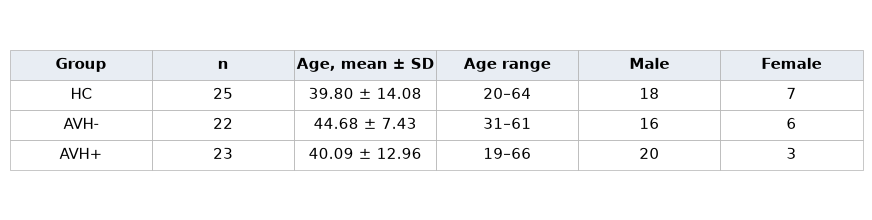

Saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\tables


In [94]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Create a folder for paper tables
TABLE_DIR = OUTPUT_DIR.parent / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

groups = ["HC", "AVH-", "AVH+"]

# Build table using the merged dataset
rows = []

for group in groups:
    subset = df_merged[df_merged["group"] == group]

    rows.append({
        "Group": group,
        "n": len(subset),
        "Age, mean ± SD": (
            f"{subset['age'].mean():.2f} ± "
            f"{subset['age'].std():.2f}"
        ),
        "Age range": (
            f"{subset['age'].min():.0f}–"
            f"{subset['age'].max():.0f}"
        ),
        "Male": (subset["sex"] == "male").sum(),
        "Female": (subset["sex"] == "female").sum()
    })

table1 = pd.DataFrame(rows)

# Save an editable CSV copy
table1.to_csv(TABLE_DIR / "Table_1_Demographics.csv", index=False)

# Create high-resolution image
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.axis("off")

tbl = ax.table(
    cellText=table1.values,
    colLabels=table1.columns,
    cellLoc="center",
    loc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 1.8)

# Simple academic formatting
for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor("#B0B0B0")
    cell.set_linewidth(0.5)
    if row == 0:
        cell.set_facecolor("#E8EDF3")
        cell.set_text_props(weight="bold")

plt.savefig(
    TABLE_DIR / "Table_1_Demographics.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", TABLE_DIR)


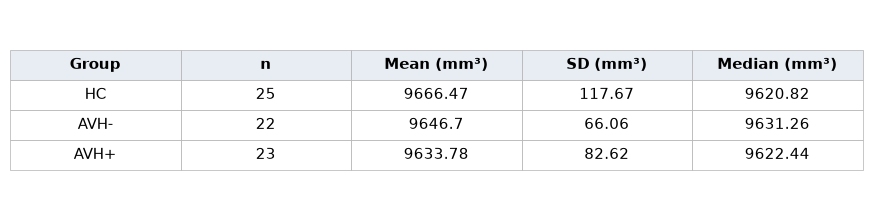

Saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\tables


In [95]:

import pandas as pd
import matplotlib.pyplot as plt

# Calculate descriptive statistics
table2 = (
    df_merged
    .groupby("group")["total_exploratory_mm3"]
    .agg(["count", "mean", "std", "median"])
    .reindex(["HC", "AVH-", "AVH+"])
    .reset_index()
)

table2.columns = [
    "Group", "n", "Mean (mm³)", "SD (mm³)", "Median (mm³)"
]

# Round numerical values
table2 = table2.round(2)

# Save editable CSV
table2.to_csv(
    TABLE_DIR / "Table_2_Bilateral_ROI.csv",
    index=False
)

# Create publication-style table
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.axis("off")

tbl = ax.table(
    cellText=table2.values,
    colLabels=table2.columns,
    cellLoc="center",
    loc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 1.8)

# Match Table 1 formatting
for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor("#B0B0B0")
    cell.set_linewidth(0.5)

    if row == 0:
        cell.set_facecolor("#E8EDF3")
        cell.set_text_props(weight="bold")

plt.savefig(
    TABLE_DIR / "Table_2_Bilateral_ROI.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", TABLE_DIR)


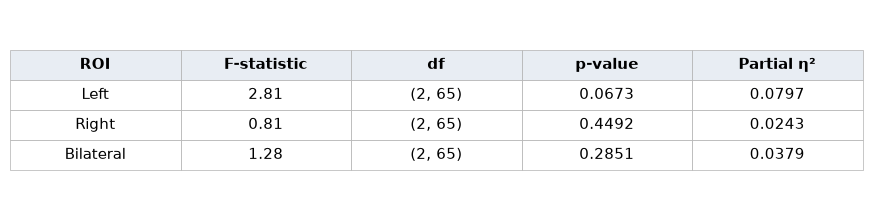

Saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\tables


,ROI,F-statistic,df,p-value,Partial η²
0,Left,2.81,"(2, 65)",0.0673,0.0797
1,Right,0.81,"(2, 65)",0.4492,0.0243
2,Bilateral,1.28,"(2, 65)",0.2851,0.0379


In [96]:

import pandas as pd
import matplotlib.pyplot as plt

# Results from your completed ANCOVA analyses
results = [
    {"ROI": "Left", "F": 2.8145, "df1": 2, "df2": 65, "p": 0.0673},
    {"ROI": "Right", "F": 0.8101, "df1": 2, "df2": 65, "p": 0.4492},
    {"ROI": "Bilateral", "F": 1.2794, "df1": 2, "df2": 65, "p": 0.2851}
]

table3 = pd.DataFrame(results)

# Calculate partial eta-squared from F and degrees of freedom
table3["Partial η²"] = (
    table3["F"] * table3["df1"]
    / (table3["F"] * table3["df1"] + table3["df2"])
)

# Format for publication
display_table = pd.DataFrame({
    "ROI": table3["ROI"],
    "F-statistic": table3["F"].map(lambda x: f"{x:.2f}"),
    "df": table3.apply(
        lambda r: f"({int(r['df1'])}, {int(r['df2'])})",
        axis=1
    ),
    "p-value": table3["p"].map(lambda x: f"{x:.4f}"),
    "Partial η²": table3["Partial η²"].map(
        lambda x: f"{x:.4f}"
    )
})

# Save editable CSV
display_table.to_csv(
    TABLE_DIR / "Table_3_ANCOVA.csv",
    index=False
)

# Generate table image
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.axis("off")

tbl = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    cellLoc="center",
    loc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 1.8)

# Match formatting of Tables 1 and 2
for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor("#B0B0B0")
    cell.set_linewidth(0.5)

    if row == 0:
        cell.set_facecolor("#E8EDF3")
        cell.set_text_props(weight="bold")

plt.savefig(
    TABLE_DIR / "Table_3_ANCOVA.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", TABLE_DIR)

display_table


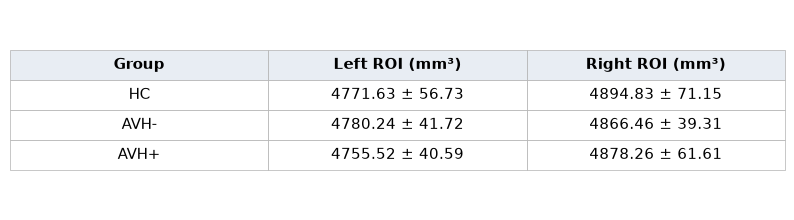

Saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\tables


In [97]:

import pandas as pd
import matplotlib.pyplot as plt

# Values from your completed analysis
table4 = pd.DataFrame({
    "Group": ["HC", "AVH-", "AVH+"],
    "Left ROI (mm³)": [
        "4771.63 ± 56.73",
        "4780.24 ± 41.72",
        "4755.52 ± 40.59"
    ],
    "Right ROI (mm³)": [
        "4894.83 ± 71.15",
        "4866.46 ± 39.31",
        "4878.26 ± 61.61"
    ]
})

# Save editable CSV
table4.to_csv(
    TABLE_DIR / "Table_4_Hemispheric_ROI.csv",
    index=False
)

# Create publication-style table
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.axis("off")

tbl = ax.table(
    cellText=table4.values,
    colLabels=table4.columns,
    cellLoc="center",
    loc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 1.8)

# Match previous tables
for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor("#B0B0B0")
    cell.set_linewidth(0.5)

    if row == 0:
        cell.set_facecolor("#E8EDF3")
        cell.set_text_props(weight="bold")

plt.savefig(
    TABLE_DIR / "Table_4_Hemispheric_ROI.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", TABLE_DIR)


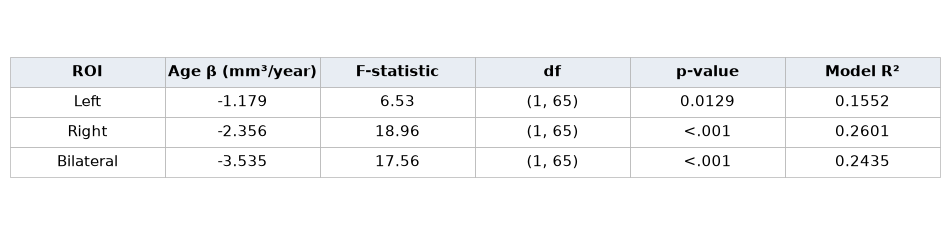

Saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\tables


,ROI,Age β (mm³/year),F-statistic,df,p-value,Model R²
0,Left,-1.179,6.53,"(1, 65)",0.0129,0.1552
1,Right,-2.356,18.96,"(1, 65)",<.001,0.2601
2,Bilateral,-3.535,17.56,"(1, 65)",<.001,0.2435


In [98]:

import pandas as pd
import matplotlib.pyplot as plt

# Results from your completed ANCOVA models
table5 = pd.DataFrame({
    "ROI": ["Left", "Right", "Bilateral"],
    "Age coefficient (mm³/year)": [-1.17913, -2.35615, -3.53528],
    "F-statistic": [6.5348, 18.9576, 17.5607],
    "df": ["(1, 65)", "(1, 65)", "(1, 65)"],
    "p-value": [0.01292, 0.000048, 0.000086],
    "Model R²": [0.1552, 0.2601, 0.2435]
})

# Format values for publication
display_table5 = pd.DataFrame({
    "ROI": table5["ROI"],
    "Age β (mm³/year)": table5[
        "Age coefficient (mm³/year)"
    ].map(lambda x: f"{x:.3f}"),
    "F-statistic": table5["F-statistic"].map(
        lambda x: f"{x:.2f}"
    ),
    "df": table5["df"],
    "p-value": table5["p-value"].map(
        lambda x: "<.001" if x < 0.001 else f"{x:.4f}"
    ),
    "Model R²": table5["Model R²"].map(
        lambda x: f"{x:.4f}"
    )
})

# Save editable CSV
display_table5.to_csv(
    TABLE_DIR / "Table_5_Age_Associations.csv",
    index=False
)

# Create high-resolution table image
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.axis("off")

tbl = ax.table(
    cellText=display_table5.values,
    colLabels=display_table5.columns,
    cellLoc="center",
    loc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 1.8)

# Match formatting of Tables 1–4
for (row, col), cell in tbl.get_celld().items():
    cell.set_edgecolor("#B0B0B0")
    cell.set_linewidth(0.5)

    if row == 0:
        cell.set_facecolor("#E8EDF3")
        cell.set_text_props(weight="bold")

plt.savefig(
    TABLE_DIR / "Table_5_Age_Associations.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Saved to:", TABLE_DIR)

display_table5


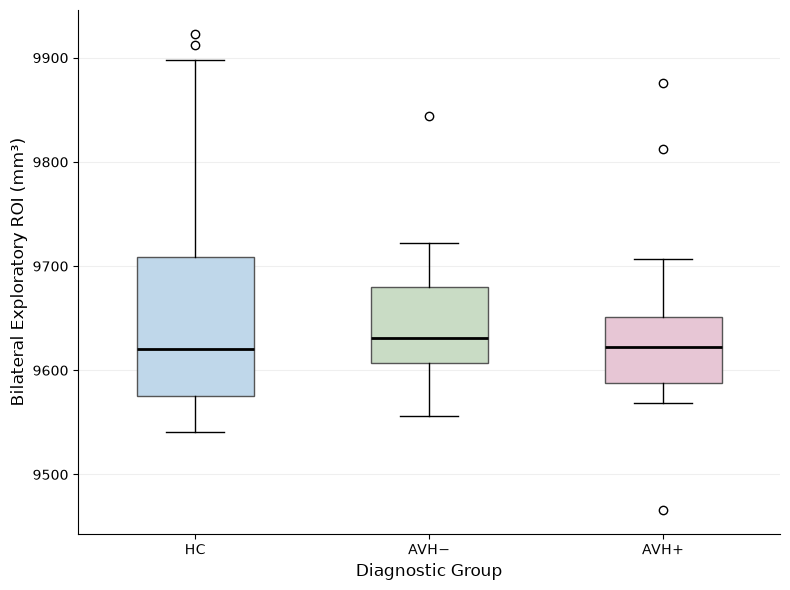

Figure saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\Figure_1_Bilateral_ROI_Boxplot.png


In [99]:

import matplotlib.pyplot as plt
import pandas as pd

# Set group order
group_order = ["HC", "AVH-", "AVH+"]

# Extract participant measurements
plot_data = [
    df_merged.loc[
        df_merged["group"] == group,
        "total_exploratory_mm3"
    ].dropna().values
    for group in group_order
]

# Create boxplot
fig, ax = plt.subplots(figsize=(8, 6))

bp = ax.boxplot(
    plot_data,
    tick_labels=["HC", "AVH−", "AVH+"],
    patch_artist=True,
    widths=0.5,
    showfliers=True,
    medianprops={"color": "black", "linewidth": 2}
)

# Format boxes
colors = ["#BFD7EA", "#C9DCC5", "#E7C6D5"]

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("#555555")

# Axis labels
ax.set_xlabel("Diagnostic Group", fontsize=12)
ax.set_ylabel("Bilateral Exploratory ROI (mm³)", fontsize=12)

# Clean academic formatting
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save image
figure_path = TABLE_DIR.parent / "Figure_1_Bilateral_ROI_Boxplot.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved to:", figure_path)


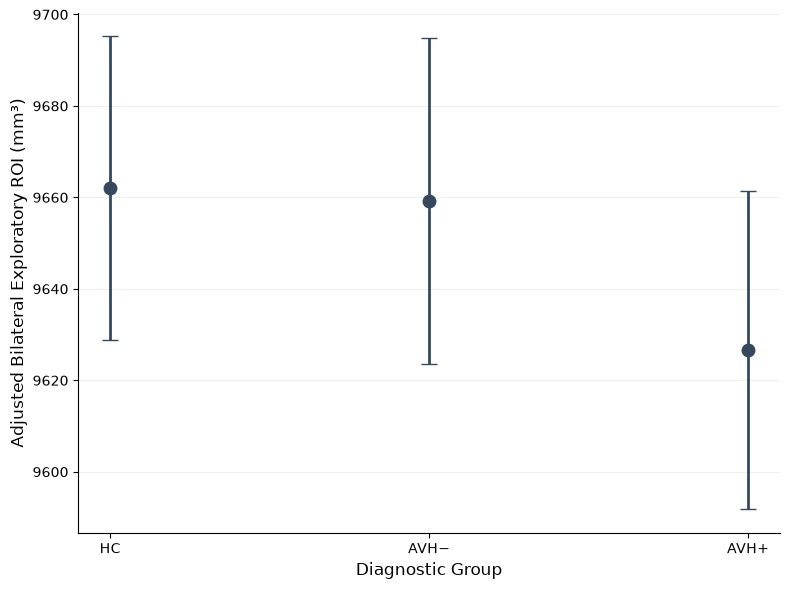

Figure saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\Figure_2_Adjusted_Group_Means.png

Adjusted group estimates:


,Group,Adjusted mean,Lower 95% CI,Upper 95% CI
0,HC,9661.98,9628.74,9695.21
1,AVH-,9659.29,9623.61,9694.96
2,AVH+,9626.63,9591.82,9661.43


In [100]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# Fit the same ANCOVA model used in your analysis
model = smf.ols(
    "total_exploratory_mm3 ~ C(group) + age + C(sex)",
    data=df_merged
).fit()

# Use the sample's mean age and observed sex distribution
# to calculate marginal adjusted group means.
groups = ["HC", "AVH-", "AVH+"]

predictions = []

for group in groups:
    # Assign every participant to this group while
    # preserving their original age and sex.
    new_data = df_merged[["age", "sex"]].copy()
    new_data["group"] = group

    # Average the model design matrix across participants
    import patsy
    design = patsy.build_design_matrices(
        [model.model.data.design_info],
        new_data
    )[0]

    x_mean = np.asarray(design).mean(axis=0)

    # Adjusted mean and its standard error
    mean = float(x_mean @ model.params.values)

    se = float(np.sqrt(
        x_mean @ model.cov_params().values @ x_mean
    ))

    from scipy.stats import t

    critical = t.ppf(0.975, model.df_resid)

    predictions.append({
        "Group": group,
        "Adjusted mean": mean,
        "Lower 95% CI": mean - critical * se,
        "Upper 95% CI": mean + critical * se
    })

adjusted_df = pd.DataFrame(predictions)

# Plot adjusted means and 95% confidence intervals
fig, ax = plt.subplots(figsize=(8, 6))

x = np.arange(len(groups))
means = adjusted_df["Adjusted mean"].values

lower_errors = (
    means - adjusted_df["Lower 95% CI"].values
)
upper_errors = (
    adjusted_df["Upper 95% CI"].values - means
)

ax.errorbar(
    x,
    means,
    yerr=[lower_errors, upper_errors],
    fmt="o",
    markersize=9,
    capsize=6,
    linewidth=2,
    color="#34495E",
    ecolor="#34495E"
)

ax.set_xticks(x)
ax.set_xticklabels(["HC", "AVH−", "AVH+"])
ax.set_xlabel("Diagnostic Group", fontsize=12)
ax.set_ylabel(
    "Adjusted Bilateral Exploratory ROI (mm³)",
    fontsize=12
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save figure and numerical estimates
figure_path = (
    TABLE_DIR.parent /
    "Figure_2_Adjusted_Group_Means.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

adjusted_df.to_csv(
    TABLE_DIR / "Figure_2_Adjusted_Means_Data.csv",
    index=False
)

plt.show()

print("Figure saved to:", figure_path)
print("\nAdjusted group estimates:")
display(adjusted_df.round(2))


['participant', 'left_exploratory_mm3', 'right_exploratory_mm3', 'total_exploratory_mm3', 'method', 'left_atlas_voxels', 'right_atlas_voxels', 'left_threshold', 'right_threshold', 'registration_metric', 'participant_id', 'age', 'sex', 'iq', 'group', 'psyrats']


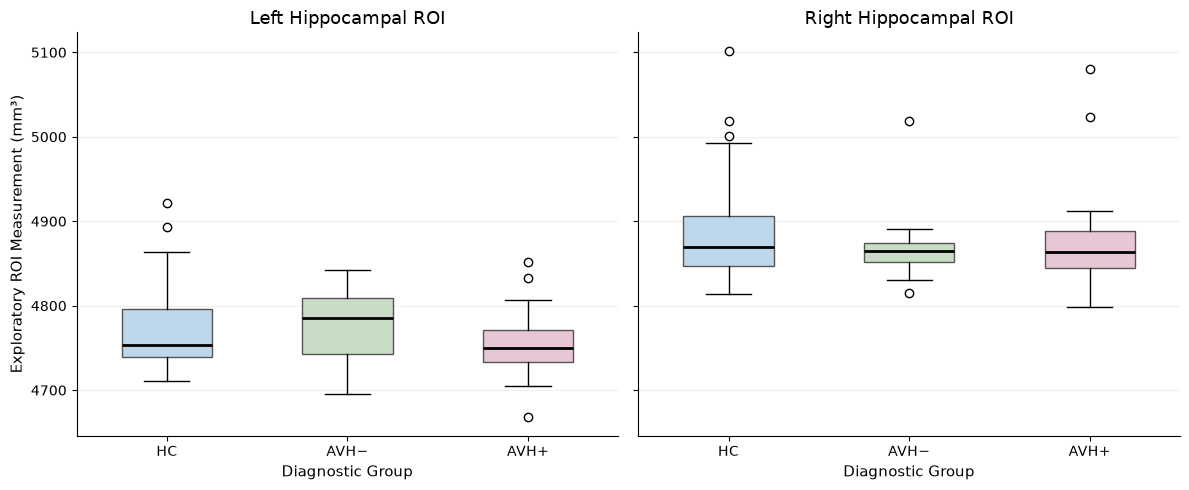

Figure saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\Figure_3_Left_Right_ROI_Boxplots.png


In [101]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Confirm your dataframe's column names if necessary
print(df_merged.columns.tolist())

# Set group order and ROI columns
groups = ["HC", "AVH-", "AVH+"]
roi_columns = [
    "left_exploratory_mm3",
    "right_exploratory_mm3"
]

colors = ["#BFD7EA", "#C9DCC5", "#E7C6D5"]

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True
)

for ax, column, title in zip(
    axes,
    roi_columns,
    ["Left Hippocampal ROI", "Right Hippocampal ROI"]
):
    data = [
        df_merged.loc[
            df_merged["group"] == group,
            column
        ].dropna().values
        for group in groups
    ]

    bp = ax.boxplot(
        data,
        tick_labels=["HC", "AVH−", "AVH+"],
        patch_artist=True,
        widths=0.5,
        showfliers=True,
        medianprops={
            "color": "black",
            "linewidth": 2
        }
    )

    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_edgecolor("#555555")

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Diagnostic Group", fontsize=11)
    ax.grid(axis="y", alpha=0.2)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel(
    "Exploratory ROI Measurement (mm³)",
    fontsize=11
)

plt.tight_layout()

# Save high-resolution figure
figure_path = (
    TABLE_DIR.parent /
    "Figure_3_Left_Right_ROI_Boxplots.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved to:", figure_path)


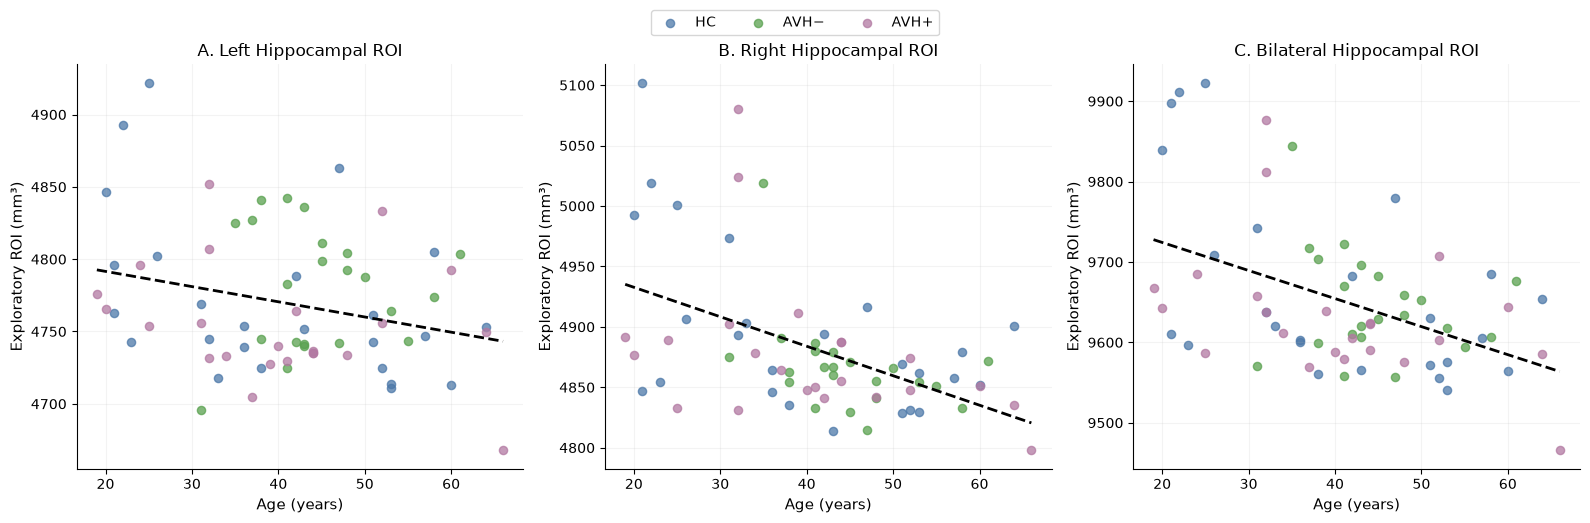

Figure saved to: C:\Users\risha\Documents\NSCI270_Hippocampus\Figure_4_Age_ROI_Associations.png


In [102]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Define ROI columns
roi_columns = [
    "left_exploratory_mm3",
    "right_exploratory_mm3",
    "total_exploratory_mm3"
]

titles = [
    "A. Left Hippocampal ROI",
    "B. Right Hippocampal ROI",
    "C. Bilateral Hippocampal ROI"
]

colors = {
    "HC": "#4C78A8",
    "AVH-": "#59A14F",
    "AVH+": "#B279A2"
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

for ax, column, title in zip(
    axes, roi_columns, titles
):
    # Plot participants by diagnostic group
    for group in ["HC", "AVH-", "AVH+"]:
        subset = df_merged[
            df_merged["group"] == group
        ]

        ax.scatter(
            subset["age"],
            subset[column],
            label=group,
            color=colors[group],
            alpha=0.75,
            s=35
        )

    # Fit unadjusted regression line
    valid = df_merged[
        ["age", column]
    ].dropna()

    slope, intercept, r, p, stderr = linregress(
        valid["age"],
        valid[column]
    )

    x_line = np.linspace(
        valid["age"].min(),
        valid["age"].max(),
        100
    )

    ax.plot(
        x_line,
        intercept + slope * x_line,
        color="black",
        linewidth=2,
        linestyle="--"
    )

    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Age (years)", fontsize=11)
    ax.set_ylabel("Exploratory ROI (mm³)", fontsize=11)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(alpha=0.15)

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    ["HC", "AVH−", "AVH+"],
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.05)
)

plt.tight_layout()

# Save figure
figure_path = (
    TABLE_DIR.parent /
    "Figure_4_Age_ROI_Associations.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved to:", figure_path)


In [103]:

from pathlib import Path

# Show available project variables
for name in [
    "OUTPUT_DIR",
    "TABLE_DIR",
    "df_merged",
    "mask_path",
    "roi_mask_path",
    "t1_path"
]:
    if name in globals():
        value = globals()[name]
        if name == "df_merged":
            print(name, ":", value.columns.tolist())
        else:
            print(name, ":", value)

# Find existing MRI and mask files
search_root = TABLE_DIR.parent if "TABLE_DIR" in globals() else Path.cwd()

nii_files = sorted(
    list(search_root.rglob("*.nii")) +
    list(search_root.rglob("*.nii.gz"))
)

print("\nAvailable NIfTI files:")
for path in nii_files[:40]:
    print(path)

print("\nTotal NIfTI files found:", len(nii_files))


OUTPUT_DIR : C:\Users\risha\Documents\NSCI270_Hippocampus\outputs
TABLE_DIR : C:\Users\risha\Documents\NSCI270_Hippocampus\tables
df_merged : ['participant', 'left_exploratory_mm3', 'right_exploratory_mm3', 'total_exploratory_mm3', 'method', 'left_atlas_voxels', 'right_atlas_voxels', 'left_threshold', 'right_threshold', 'registration_metric', 'participant_id', 'age', 'sex', 'iq', 'group', 'psyrats']

Available NIfTI files:
C:\Users\risha\Documents\NSCI270_Hippocampus\data\sub-01_T1w.nii.gz
C:\Users\risha\Documents\NSCI270_Hippocampus\data\sub-02_T1w.nii.gz
C:\Users\risha\Documents\NSCI270_Hippocampus\data\sub-03_T1w.nii.gz
C:\Users\risha\Documents\NSCI270_Hippocampus\data\sub-04_T1w.nii.gz
C:\Users\risha\Documents\NSCI270_Hippocampus\data\sub-05_T1w.nii.gz
C:\Users\risha\Documents\NSCI270_Hippocampus\data\sub-06_T1w.nii.gz
C:\Users\risha\Documents\NSCI270_Hippocampus\data\sub-07_T1w.nii.gz
C:\Users\risha\Documents\NSCI270_Hippocampus\data\sub-08_T1w.nii.gz
C:\Users\risha\Documents\NSCI